# Cancer Support Netherlands CSN


## Buisness Context/ Project Goal
This project aims to create a structured English-language cancer navigation knowledge base from trusted Dutch healthcare sources for Cancer Support Netherlands (CSN).

The dataset is designed to support future patient navigation tools by organising information according to patient journey stages, topics, stakeholders and practical next steps.


## Methodology

This notebook builds the first-stage discovery and review dataset for the CSN cancer navigation knowledge base.

The workflow is:

1. Define the project taxonomy for journey stages, topics and stakeholders.
2. Crawl approved Dutch healthcare websites to collect candidate links.
3. Translate key link metadata into English, including link text and URL sections where available.
4. Combine all discovered links into `discovered_links_df` and export it to `data/discovered_links_df.csv`.
5. Explore the discovered links with EDA, including source coverage, missing values, crawl depth, duplicate URLs and URL discovery frequency.
6. Use translated metadata, word-frequency analysis and word clouds to support keyword development.
7. Apply noise and topic keyword rules to create a shortlist for manual review.
8. Deduplicate the shortlist by URL and export the final manual review file to `data/manual_review_links_df.csv`.

Key outputs from this notebook:

- `discovered_links_df`: all links collected from the approved source websites.
- `url_discovery_summary_df`: one row per URL showing discovery count and source-page coverage.
- `shortlisted_links_review_df`: keyword-matched links before deduplication.
- `manual_review_df`: deduplicated links prepared for manual review.


In [121]:
# imports and project paths
import re
import time
import unicodedata
from collections import Counter, deque
from pathlib import Path
from urllib.parse import urljoin, urlparse

import pandas as pd
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup

try:
    from deep_translator import GoogleTranslator
except ImportError as exc:
    GoogleTranslator = None
    DEEP_TRANSLATOR_IMPORT_ERROR = exc

try:
    from wordcloud import WordCloud
except ImportError:
    WordCloud = None

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

DISCOVERED_LINKS_PATH = DATA_DIR / "discovered_links_df.csv"
MANUAL_REVIEW_PATH = DATA_DIR / "manual_review_links_df.csv"
URL_DISCOVERY_SUMMARY_PATH = DATA_DIR / "url_discovery_summary_df.csv"


## Taxonomy


In [3]:
# define journey stages
journey_stages = pd.DataFrame([
    {
        "journey_stage": "Care Pathway",
        "description": "Treatment, decision making, ongoing care navigation, referals, cost etc"
    },
    {
        "journey_stage": "Orientation",
        "description": "understanding the ducth healthcare system and cancer care structure"
    },
    {
        "journey_stage": "First 48 hours",
        "description": "Immediate guidance and support"
    },
    {
        "journey_stage": "Active Navigation",
        "description": "Managing ongoing treatment"
    },
    # last one for optional resources
    {
        "journey_stage": "Rights & Support",
        "description": ""
    }
])
journey_stages

,journey_stage,description
0,Care Pathway,"Treatment, decision making, ongoing care navig..."
1,Orientation,understanding the ducth healthcare system and ...
2,First 48 hours,Immediate guidance and support
3,Active Navigation,Managing ongoing treatment
4,Rights & Support,


In [4]:
# Define Topics
# mainly extracted from community questions
topics = pd.DataFrame([
    {"topic": "Referals and process"},
    {"topic": "Waiting times"},
    {"topic": "Treatment decisions"},
    {"topic": "Second opinions"},
    {"topic": "Insurance Coverage and costs"},

])
topics

,topic
0,Referals and process
1,Waiting times
2,Treatment decisions
3,Second opinions
4,Insurance Coverage and costs


In [5]:
# define stakeholders
stakeholders = pd.DataFrame([
    {"stakeholder": "GP"},
    {"stakeholder": "Specialist"},
    {"stakeholder": "Hospital"},
    {"stakeholder": "Insurer"},
    {"stakeholder": "Physiotherapist"}

])
stakeholders

,stakeholder
0,GP
1,Specialist
2,Hospital
3,Insurer
4,Physiotherapist


## Source inventory/ website discovery

in this section we build source inventory by collecting all link then filter them out by the usefulness to our porject

In [158]:
# discovered links df
discovered_links_columns = [

    # source info
    "source_organisation",

    # crawl metadata
    "source_page",
    "depth",

    # link info
    "link_text",
    "link_text_en",

    "href",
    "full_url",

    # url structure
    "url_section",
    "url_section_en",

    # cleaning/review flags
    "is_selected",
    "is_noise",
    "review_notes"
]

discovered_links_df = pd.DataFrame(
    columns=discovered_links_columns
)

discovered_links_df

,source_organisation,source_page,depth,link_text,link_text_en,href,full_url,url_section,url_section_en,is_selected,is_noise,review_notes


In [126]:
# source inventory links should answer these questions
# why are we scraping this page
# which patient/comunity question does it answer
# which topic does it belong to
# which stage does it cover

source_inventory_columns = [

    # source info
    "source_organisation",

    # page identity
    "source_page_title",
    "source_page_title_en",

    "url",

    # website structure
    "url_section",
    "url_section_en",

    # project taxonomy
    "journey_stage",
    "page_topic",
    "patient_question",
    "stakeholder",

    # operational metadata
    "priority_level",
    "scrape_status",
    "translation_status",
    "review_status",

    # notes
    "notes"
]
source_inventory_df = pd.DataFrame(
    columns=source_inventory_columns
)

source_inventory_df

,source_organisation,source_page_title,source_page_title_en,url,url_section,url_section_en,journey_stage,page_topic,patient_question,stakeholder,priority_level,scrape_status,translation_status,review_status,notes


In [7]:
# functions

# google translate function
# translate Dutch text into English
# used later for:
# - link_text
# - url_section
# - page content (note: slow for long content)
def translate_text(text):
    if GoogleTranslator is None:
        raise ImportError(
            "Install deep-translator before running translation cells: "
            "pip install deep-translator"
        ) from DEEP_TRANSLATOR_IMPORT_ERROR

    try:
        return GoogleTranslator(
            source="auto",
            target="en"
        ).translate(text)
    except Exception:
        return None

# extract URL section from href
# e.g: /hulp-en-ondersteuning/appstore -> hulp-en-ondersteuning
# e.g  homepage "/" returns "homepage"
def get_url_section(url):
    path = urlparse(url).path
    parts = path.strip("/").split("/")
    return parts[0] if parts and parts[0] else "homepage"


# calculate url depth
# e.g: /a/b/c -> depth = 3
# use to control crawling
def url_depth(url):
    path = urlparse(url).path
    return len([part for part in path.split("/") if part])


# initial filtering
# rules:
# - same domain only
# - remove anchor links (#)
# - remove pagination/query links (?)
# - avoid very deep URLs
# - ignore blocked sections
def is_valid_url(url, base_domain, blocked_sections=None, max_url_depth=6):
    if blocked_sections is None:
        blocked_sections = []

    parsed = urlparse(url)

    # keep only same-domain pages
    if parsed.netloc and parsed.netloc != base_domain:
        return False

    # remove anchor links like #main-content
    if parsed.fragment:
        return False

    # remove query links like ?page=1
    if parsed.query:
        return False

    # avoid very deep pages
    if url_depth(url) > max_url_depth:
        return False

    section = get_url_section(url)

    # ignore blocked links such as user login

    if section in blocked_sections:
        return False

    return True


# scrape a webpage and extract:
# - href
# - link text
# - full URL
# - URL section
def extract_links(
    url,
    depth,
    base_url,
    base_domain,
    headers,
    blocked_sections=None,
    max_url_depth=6
):
    response = requests.get(url, headers=headers, timeout=10)

    if response.status_code != 200:
        return []

    soup = BeautifulSoup(response.text, "html.parser")

    links = []

    for a in soup.find_all("a", href=True):
        href = a["href"]
        link_text = a.get_text(" ", strip=True)

        if len(link_text) < 3:
            continue

        if link_text.lower() in ["volgende", "vorige", "next", "previous"]:
            continue

        full_url = urljoin(base_url, href)

        if not is_valid_url(
            full_url,
            base_domain=base_domain,
            blocked_sections=blocked_sections,
            max_url_depth=max_url_depth
        ):
            continue

        links.append({
            "source_page": url,
            "depth": depth,
            "link_text": link_text,
            "href": href,
            "full_url": full_url,
            "url_section": get_url_section(full_url)
        })

    return links



# Main crawler function
# recursively crawl a website
# workflow:
# start page
# -> extract links -> visit discovered links -> repeat until max depth/pages reached
# returns: dataframe of discovered links
def crawl_site(
    start_url,
    base_url,
    base_domain,
    source_organisation,
    blocked_sections=None,
    headers=None,
    max_depth=2,
    max_pages=50,
    max_url_depth=6,
    sleep_seconds=1
):
    if blocked_sections is None:
        blocked_sections = []

    if headers is None:
        headers = {"User-Agent": "Mozilla/5.0"}

    visited = set()
    queue = deque([(start_url, 0)])
    all_links = []

    while queue and len(visited) < max_pages:
        current_url, depth = queue.popleft()

        if current_url in visited:
            continue

        visited.add(current_url)

        print(f"Scraping depth {depth}: {current_url}")

        try:
            links = extract_links(
                url=current_url,
                depth=depth,
                base_url=base_url,
                base_domain=base_domain,
                headers=headers,
                blocked_sections=blocked_sections,
                max_url_depth=max_url_depth
            )

            all_links.extend(links)

            if depth < max_depth:
                for link in links:
                    next_url = link["full_url"]

                    if next_url not in visited:
                        queue.append((next_url, depth + 1))

            time.sleep(sleep_seconds)

        except Exception as e:
            print(f"Failed: {current_url}")
            print(e)

    df = pd.DataFrame(all_links)

    if not df.empty:
        df["source_organisation"] = source_organisation

    return df


# whole column translation function
# translate unique values once, then map translations back
def add_translated_column(
    df,
    source_column,
    translated_column,
    translate_function
):
    """
    Translate unique values from a column
    and map them back to the dataframe.
    """

    # get unique non-null values
    unique_values = (
        df[source_column]
        .dropna()
        .unique()
    )

    # build translation dictionary
    translation_dict = {}

    for value in unique_values:

        translated = translate_function(value)

        translation_dict[value] = translated

    # map translations back to dataframe
    df[translated_column] = df[source_column].map(
        translation_dict
    )

    return df, translation_dict


### kanker

In [8]:
# kanker main page
# define inputs
start_url="https://www.kanker.nl/"
base_url="https://www.kanker.nl"
base_domain="www.kanker.nl"
source_organisation="kanker.nl"
blocked_sections= ["user", "overig"]
headers = {
    "User-Agent": "Mozilla/5.0"
}


response = requests.get(base_url, headers=headers)
print("homepage response:", response.status_code)

kanker_links_df = crawl_site(
    start_url=start_url,
    base_url=base_url,
    base_domain=base_domain,
    source_organisation=source_organisation,
    blocked_sections=blocked_sections,
    max_depth=4,
    max_pages=50
)

kanker_links_df

homepage response: 200
Scraping depth 0: https://www.kanker.nl/
Scraping depth 1: https://www.kanker.nl/ervaringen-van-anderen/blogs
Scraping depth 1: https://www.kanker.nl/ervaringen-van-anderen/gespreksgroepen
Scraping depth 1: https://www.kanker.nl/diagnose
Scraping depth 1: https://www.kanker.nl/jong
Scraping depth 1: https://www.kanker.nl/ervaringen-van-anderen/lotgenotenzoeker
Scraping depth 1: https://www.kanker.nl/hulp-en-ondersteuning/stel-je-vraag-aan-een-professional
Scraping depth 1: https://www.kanker.nl/hulp-en-ondersteuning/de-kankernl-infolijn
Scraping depth 1: https://www.kanker.nl/hulp-en-ondersteuning/vind-hulp-bij-kanker
Scraping depth 1: https://www.kanker.nl/hulp-en-ondersteuning/appstore
Scraping depth 1: https://www.kanker.nl/agenda
Scraping depth 1: https://www.kanker.nl/patientenorganisaties
Scraping depth 1: https://www.kanker.nl/ipso
Scraping depth 1: https://www.kanker.nl/kankersoorten
Scraping depth 1: https://www.kanker.nl/kankersoorten/alvleesklierkanker

,source_page,depth,link_text,href,full_url,url_section,source_organisation
0,https://www.kanker.nl/,0,We zijn er voor je. Kanker.nl,/,https://www.kanker.nl/,homepage,kanker.nl
1,https://www.kanker.nl/,0,Blogs,/ervaringen-van-anderen/blogs,https://www.kanker.nl/ervaringen-van-anderen/b...,ervaringen-van-anderen,kanker.nl
2,https://www.kanker.nl/,0,In gesprek met elkaar,/ervaringen-van-anderen/gespreksgroepen,https://www.kanker.nl/ervaringen-van-anderen/g...,ervaringen-van-anderen,kanker.nl
3,https://www.kanker.nl/,0,Diagnose,/diagnose,https://www.kanker.nl/diagnose,diagnose,kanker.nl
4,https://www.kanker.nl/,0,Jong & kanker (16 t/m 39),/jong,https://www.kanker.nl/jong,jong,kanker.nl
...,...,...,...,...,...,...,...
4502,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Project Kanker & werk,https://www.kanker.nl/project-kanker-en-werk,https://www.kanker.nl/project-kanker-en-werk,project-kanker-en-werk,kanker.nl
4503,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Wetenschappelijk onderzoek,/wetenschappelijk-onderzoek,https://www.kanker.nl/wetenschappelijk-onderzoek,wetenschappelijk-onderzoek,kanker.nl
4504,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Voor zorgprofessionals,/zorgprofessionals,https://www.kanker.nl/zorgprofessionals,zorgprofessionals,kanker.nl
4505,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Woordenboeken,/zorgprofessionals/woordenboeken,https://www.kanker.nl/zorgprofessionals/woorde...,zorgprofessionals,kanker.nl


In [9]:
# url section value count:
print("number of unique values of url section")
print(kanker_links_df["url_section"].nunique())
kanker_links_df["url_section"].value_counts()

number of unique values of url section
44


url_section
kankersoorten                          1830
soorten-behandelingen                   484
hulp-en-ondersteuning                   411
gevolgen-van-kanker                     399
ervaringen-van-anderen                  299
over-ons                                150
zorgprofessionals                       150
homepage                                115
agenda                                   55
ipso                                     53
patientenorganisaties                    52
naasten                                  52
jong                                     51
verder-met-je-leven-na-kanker            51
diagnose                                 50
operatie                                 50
nieuwsberichten                          50
project-kanker-en-werk                   50
wetenschappelijk-onderzoek               50
vind-hulp-bij-kanker                     33
algemene-onderwerpen                     25
wereld                                    4
karel               

In [10]:
# add url section in english
kanker_links_df, url_section_translation_dict = add_translated_column(
    df=kanker_links_df,
    source_column="url_section",
    translated_column="url_section_en",
    translate_function=translate_text
)

In [11]:
# url section English value count:
print("number of unique values of url section")
print(kanker_links_df["url_section_en"].nunique())
kanker_links_df["url_section_en"].value_counts()

number of unique values of url section
44


url_section_en
cancers                                 1830
species treatments                       484
help-and-support                         411
consequences-of-cancer                   399
experiences-of-others                    299
over-ons                                 150
healthcare professionals                 150
homepage                                 115
agenda                                    55
ipso                                      53
patient organizations                     52
relatives                                 52
jong                                      51
continue-with-your-life-after-cancer      51
diagnose                                  50
operation                                 50
news reports                              50
project-cancer-and-work                   50
scientific research                       50
find-help-for-cancer                      33
general-topics                            25
world                                   

In [12]:
# url text count:
print(kanker_links_df["link_text"].nunique())
kanker_links_df["link_text"].value_counts()

1441


link_text
We zijn er voor je. Kanker.nl                                                                                                                           100
Appstore                                                                                                                                                 59
Diagnose                                                                                                                                                 56
Niet meer beter worden                                                                                                                                   56
Chemotherapie                                                                                                                                            55
                                                                                                                                                       ... 
Nzinga De wereld van één grote waas "Als je kanker kri

In [13]:
# text link take too long to translate, lets inspect why
# link text df
link_texts_df = kanker_links_df[["link_text"]].copy()
link_texts_df

,link_text
0,We zijn er voor je. Kanker.nl
1,Blogs
2,In gesprek met elkaar
3,Diagnose
4,Jong & kanker (16 t/m 39)
...,...
4502,Project Kanker & werk
4503,Wetenschappelijk onderzoek
4504,Voor zorgprofessionals
4505,Woordenboeken


In [14]:
#  Check NaN values
link_texts_df["link_text"].isna().sum()

np.int64(0)

In [15]:
# check for duplicates
link_texts_df["link_text"].duplicated().sum()

np.int64(3066)

In [16]:
# add text length to inspect length
link_texts_df["length"] = link_texts_df["link_text"].str.len()
link_texts_df["length"].describe()
# observation some link text are very long
# observation: average length is 24

count    4507.000000
mean       23.626803
std        22.300177
min         3.000000
25%        11.000000
50%        20.000000
75%        29.000000
max       286.000000
Name: length, dtype: float64

In [17]:
# Sort by longest text
link_texts_df = link_texts_df.sort_values(
    "length",
    ascending=False
).reset_index(drop=True)

link_texts_df.head(10)

,link_text,length
0,In gesprek over darmkanker Ab is met de gebrui...,286
1,In gesprek over hersentumoren Moderator Han he...,281
2,In gesprek over lymfeklierkanker Moderator Rom...,280
3,In gesprek over longkanker Moderatoren Brigitt...,263
4,In gesprek over huidkanker Vragen stellen of e...,261
5,Vraag het een professional Heb je een vraag ov...,248
6,Vraag het een professional Heb je een vraag ov...,244
7,In gesprek over alvleesklierkanker Vragen stel...,243
8,Vraag het een professional Heb je een vraag ov...,241
9,Vraag het een professional Heb je een vraag ov...,230


In [18]:
# translate first 10
link_texts_top10_df = link_texts_df.head(10).copy()
link_texts_top10_df, top10_translation_dict = add_translated_column(
    df=link_texts_top10_df,
    source_column="link_text",
    translated_column="link_text_en",
    translate_function=translate_text
)

link_texts_top10_df

# observation these might be useful links so
# check for other long text ??
# TODO: check with the team

,link_text,length,link_text_en
0,In gesprek over darmkanker Ab is met de gebrui...,286,"In conversation about colon cancer Ab, with th..."
1,In gesprek over hersentumoren Moderator Han he...,281,In conversation about brain tumors Moderator H...
2,In gesprek over lymfeklierkanker Moderator Rom...,280,In conversation about lymphoma. Moderator Romy...
3,In gesprek over longkanker Moderatoren Brigitt...,263,In conversation about lung cancer Moderators B...
4,In gesprek over huidkanker Vragen stellen of e...,261,Talking about skin cancer Want to ask question...
5,Vraag het een professional Heb je een vraag ov...,248,Ask a professional Do you have a question abou...
6,Vraag het een professional Heb je een vraag ov...,244,Ask a professional Do you have a question abou...
7,In gesprek over alvleesklierkanker Vragen stel...,243,Talking about pancreatic cancer Ask questions ...
8,Vraag het een professional Heb je een vraag ov...,241,Ask a professional Do you have a question abou...
9,Vraag het een professional Heb je een vraag ov...,230,Ask a professional Do you have a question abou...


In [19]:
# add link text in english
kanker_links_df, link_text_translation_dict = add_translated_column(
    df=kanker_links_df,
    source_column="link_text",
    translated_column="link_text_en",
    translate_function=translate_text
)


In [20]:
# url_text_en count:
print(kanker_links_df["link_text_en"].nunique())
kanker_links_df["link_text_en"].value_counts()
# TODO:
# some links start with image they might be just image card links and probably should be removed

1434


link_text_en
We are here for you. Kanker.nl                                                                                                                                               100
Appstore                                                                                                                                                                      59
Diagnose                                                                                                                                                                      56
Not getting better anymore                                                                                                                                                    56
chemotherapy                                                                                                                                                                  55
                                                                                                      

In [135]:
# final check
kanker_links_df

,source_organisation,source_page,depth,link_text,link_text_en,href,full_url,url_section,url_section_en,is_selected,is_noise,review_notes
0,kanker.nl,https://www.kanker.nl/,0,We zijn er voor je. Kanker.nl,We are here for you. Kanker.nl,/,https://www.kanker.nl/,homepage,homepage,None,None,None
1,kanker.nl,https://www.kanker.nl/,0,Blogs,Blogs,/ervaringen-van-anderen/blogs,https://www.kanker.nl/ervaringen-van-anderen/b...,ervaringen-van-anderen,experiences-of-others,None,None,None
2,kanker.nl,https://www.kanker.nl/,0,In gesprek met elkaar,In conversation with each other,/ervaringen-van-anderen/gespreksgroepen,https://www.kanker.nl/ervaringen-van-anderen/g...,ervaringen-van-anderen,experiences-of-others,None,None,None
3,kanker.nl,https://www.kanker.nl/,0,Diagnose,Diagnose,/diagnose,https://www.kanker.nl/diagnose,diagnose,diagnose,None,None,None
4,kanker.nl,https://www.kanker.nl/,0,Jong & kanker (16 t/m 39),Jong & kanker (16 t/m 39),/jong,https://www.kanker.nl/jong,jong,jong,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...
4502,kanker.nl,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Project Kanker & werk,Project Cancer & work,https://www.kanker.nl/project-kanker-en-werk,https://www.kanker.nl/project-kanker-en-werk,project-kanker-en-werk,project-cancer-and-work,None,None,None
4503,kanker.nl,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Wetenschappelijk onderzoek,Scientific research,/wetenschappelijk-onderzoek,https://www.kanker.nl/wetenschappelijk-onderzoek,wetenschappelijk-onderzoek,scientific research,None,None,None
4504,kanker.nl,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Voor zorgprofessionals,For healthcare professionals,/zorgprofessionals,https://www.kanker.nl/zorgprofessionals,zorgprofessionals,healthcare professionals,None,None,None
4505,kanker.nl,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Woordenboeken,Dictionaries,/zorgprofessionals/woordenboeken,https://www.kanker.nl/zorgprofessionals/woorde...,zorgprofessionals,healthcare professionals,None,None,None


In [159]:
# append to discovered_links_df

# add missing review/cleaning columns
kanker_links_df["is_selected"] = None
kanker_links_df["is_noise"] = None
kanker_links_df["review_notes"] = None

# reorder columns to match discovered_links_df structure
kanker_links_df = kanker_links_df[
    discovered_links_columns
]

# append to discovered_links_df
discovered_links_df = pd.concat(
    [
        discovered_links_df,
        kanker_links_df
    ],
    ignore_index=True
)

# inspect
discovered_links_df.shape

discovered_links_df

,source_organisation,source_page,depth,link_text,link_text_en,href,full_url,url_section,url_section_en,is_selected,is_noise,review_notes
0,kanker.nl,https://www.kanker.nl/,0,We zijn er voor je. Kanker.nl,We are here for you. Kanker.nl,/,https://www.kanker.nl/,homepage,homepage,None,None,None
1,kanker.nl,https://www.kanker.nl/,0,Blogs,Blogs,/ervaringen-van-anderen/blogs,https://www.kanker.nl/ervaringen-van-anderen/b...,ervaringen-van-anderen,experiences-of-others,None,None,None
2,kanker.nl,https://www.kanker.nl/,0,In gesprek met elkaar,In conversation with each other,/ervaringen-van-anderen/gespreksgroepen,https://www.kanker.nl/ervaringen-van-anderen/g...,ervaringen-van-anderen,experiences-of-others,None,None,None
3,kanker.nl,https://www.kanker.nl/,0,Diagnose,Diagnose,/diagnose,https://www.kanker.nl/diagnose,diagnose,diagnose,None,None,None
4,kanker.nl,https://www.kanker.nl/,0,Jong & kanker (16 t/m 39),Jong & kanker (16 t/m 39),/jong,https://www.kanker.nl/jong,jong,jong,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...
4502,kanker.nl,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Project Kanker & werk,Project Cancer & work,https://www.kanker.nl/project-kanker-en-werk,https://www.kanker.nl/project-kanker-en-werk,project-kanker-en-werk,project-cancer-and-work,None,None,None
4503,kanker.nl,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Wetenschappelijk onderzoek,Scientific research,/wetenschappelijk-onderzoek,https://www.kanker.nl/wetenschappelijk-onderzoek,wetenschappelijk-onderzoek,scientific research,None,None,None
4504,kanker.nl,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Voor zorgprofessionals,For healthcare professionals,/zorgprofessionals,https://www.kanker.nl/zorgprofessionals,zorgprofessionals,healthcare professionals,None,None,None
4505,kanker.nl,https://www.kanker.nl/ervaringen-van-anderen/g...,1,Woordenboeken,Dictionaries,/zorgprofessionals/woordenboeken,https://www.kanker.nl/zorgprofessionals/woorde...,zorgprofessionals,healthcare professionals,None,None,None


In [160]:
# inspect
discovered_links_df["source_organisation"].value_counts()

source_organisation
kanker.nl    4507
Name: count, dtype: int64

In [24]:
# save discovered links dataset
discovered_links_df.to_csv(
    DISCOVERED_LINKS_PATH,
    index=False
)
print(f"discovered_links_df saved successfully: {DISCOVERED_LINKS_PATH}")

discovered_links_df saved successfully: data/discovered_links_df.csv


## Thuisarts

In [25]:
# define inputs
start_url = "https://www.thuisarts.nl/overzicht/onderwerpen#K"
base_url = "https://www.thuisarts.nl"
base_domain = "www.thuisarts.nl"
source_organisation = "thuisarts.nl"

headers = {
    "User-Agent": "Mozilla/5.0"
}

# TODO:
blocked_sections = [
    "user",
    "over",
    "privacy",
    "cookies"
]

response = requests.get(start_url, headers=headers)

print("response:", response.status_code)

response: 200


In [26]:
# crawl Thuisarts links using the shared crawler
thuisarts_links_df = crawl_site(
    start_url=start_url,
    base_url=base_url,
    base_domain=base_domain,
    source_organisation=source_organisation,
    blocked_sections=blocked_sections,
    headers=headers,
    max_depth=2,
    max_pages=50
)

thuisarts_links_df

Scraping depth 0: https://www.thuisarts.nl/overzicht/onderwerpen#K
Scraping depth 1: https://www.thuisarts.nl/app-van-thuisarts
Scraping depth 1: https://www.thuisarts.nl/zoeken
Scraping depth 1: https://www.thuisarts.nl/spoed-wie-bel-je
Scraping depth 1: https://www.thuisarts.nl/overzicht/onderwerpen
Scraping depth 1: https://www.thuisarts.nl/overzicht/videos
Scraping depth 1: https://www.thuisarts.nl/overzicht/afbeeldingen
Scraping depth 1: https://www.thuisarts.nl/overzicht/keuzekaarten
Scraping depth 1: https://www.thuisarts.nl/overzicht/keuzehulpen
Scraping depth 1: https://www.thuisarts.nl/anatomisch
Scraping depth 1: https://www.thuisarts.nl/aambeien
Scraping depth 1: https://www.thuisarts.nl/aangezichtspijn
Scraping depth 1: https://www.thuisarts.nl/aangezichtsverlamming-van-bell
Scraping depth 1: https://www.thuisarts.nl/aanvallen-van-duizeligheid-bij-of-na-migraine
Scraping depth 1: https://www.thuisarts.nl/aardbeivlek
Scraping depth 1: https://www.thuisarts.nl/zwangerschap-s

,source_page,depth,link_text,href,full_url,url_section,source_organisation
0,https://www.thuisarts.nl/overzicht/onderwerpen#K,0,Bekijk,/app-van-thuisarts,https://www.thuisarts.nl/app-van-thuisarts,app-van-thuisarts,thuisarts.nl
1,https://www.thuisarts.nl/overzicht/onderwerpen#K,0,Open de zoekbalk,/zoeken,https://www.thuisarts.nl/zoeken,zoeken,thuisarts.nl
2,https://www.thuisarts.nl/overzicht/onderwerpen#K,0,Spoed: wie bellen?,/spoed-wie-bel-je,https://www.thuisarts.nl/spoed-wie-bel-je,spoed-wie-bel-je,thuisarts.nl
3,https://www.thuisarts.nl/overzicht/onderwerpen#K,0,Alle klachten en ziektes,/overzicht/onderwerpen,https://www.thuisarts.nl/overzicht/onderwerpen,overzicht,thuisarts.nl
4,https://www.thuisarts.nl/overzicht/onderwerpen#K,0,Video's,/overzicht/videos,https://www.thuisarts.nl/overzicht/videos,overzicht,thuisarts.nl
...,...,...,...,...,...,...,...
3611,https://www.thuisarts.nl/bacteriele-gewrichtso...,1,Video's,/overzicht/videos,https://www.thuisarts.nl/overzicht/videos,overzicht,thuisarts.nl
3612,https://www.thuisarts.nl/bacteriele-gewrichtso...,1,Afbeeldingen,/overzicht/afbeeldingen,https://www.thuisarts.nl/overzicht/afbeeldingen,overzicht,thuisarts.nl
3613,https://www.thuisarts.nl/bacteriele-gewrichtso...,1,Keuzehulpen,/overzicht/keuzehulpen,https://www.thuisarts.nl/overzicht/keuzehulpen,overzicht,thuisarts.nl
3614,https://www.thuisarts.nl/bacteriele-gewrichtso...,1,Keuzekaarten,/overzicht/keuzekaarten,https://www.thuisarts.nl/overzicht/keuzekaarten,overzicht,thuisarts.nl


In [27]:
# check depth reached
thuisarts_links_df["depth"].value_counts()

depth
1    2893
0     723
Name: count, dtype: int64

In [28]:
 # url text count:
print("length:", len(thuisarts_links_df))
print("unique url sections:", thuisarts_links_df["url_section"].nunique())

thuisarts_links_df["url_section"].value_counts()

length: 3616
unique url sections: 718


url_section
overzicht                              810
spoed-wie-bel-je                       150
homepage                               127
anatomisch                             118
deel-via-email                          84
                                      ... 
zweepwormen                              2
zwemmersjeuk                             2
zweten                                   2
evenwichts-migraine                      1
bacteri%C3%ABle-gewrichtsontsteking      1
Name: count, Length: 718, dtype: int64

In [29]:
# translate Thuisarts URL sections to English
thuisarts_links_df, thuisarts_section_translation_dict = add_translated_column(
    df=thuisarts_links_df,
    source_column="url_section",
    translated_column="url_section_en",
    translate_function=translate_text
)

thuisarts_links_df["url_section_en"].value_counts()

url_section_en
Overview                              810
urgent-who-call-you                   150
homepage                              127
anatomical                            118
share-via-email                        84
                                     ... 
whipworms                               2
swimmer's itch                          2
sweating                                2
equilibrium migraine                    1
bacteri%C3%ABle joint inflammation      1
Name: count, Length: 717, dtype: int64

In [30]:
# unique link text count
print("unique link text:", thuisarts_links_df["link_text"].nunique())

# value counts
thuisarts_links_df["link_text"].value_counts()

unique link text: 1245


link_text
Spoed: wie bellen?                                          150
Alle klachten en ziektes                                    100
Video's                                                     100
Afbeeldingen                                                100
Keuzekaarten                                                100
                                                           ... 
Mijn kind heeft luier-uitslag                                 1
Mijn baby heeft vieze oogjes                                  1
Mijn baby spuugt veel (reflux)                                1
Mijn baby zat tijdens de bevalling vast met de schouder       1
Ik heb een ontsteking in mijn gewricht door een bacterie      1
Name: count, Length: 1245, dtype: int64

In [31]:
# translate
thuisarts_links_df, thuisarts_link_translation_dict = add_translated_column(
    df=thuisarts_links_df,
    source_column="link_text",
    translated_column="link_text_en",
    translate_function=translate_text
)


In [32]:
# unique link text en
print("unique link text en:", thuisarts_links_df["link_text_en"].nunique())

thuisarts_links_df["link_text_en"].value_counts()

unique link text en: 1243


link_text_en
Emergency: who to call?                                 150
All complaints and illnesses                            100
Video's                                                 100
Images                                                  100
Choice cards                                            100
                                                       ... 
My child has diaper rash                                  1
My baby has dirty eyes                                    1
My baby spits up a lot (reflux)                           1
My baby's shoulder was stuck during delivery              1
I have an inflammation in my joint due to a bacteria      1
Name: count, Length: 1243, dtype: int64

In [33]:
# add review columns
thuisarts_links_df["is_selected"] = None
thuisarts_links_df["is_noise"] = None
thuisarts_links_df["review_notes"] = None


In [34]:
#  reorder columns to match discovered links df
thuisarts_links_df = thuisarts_links_df[
    discovered_links_columns
]

thuisarts_links_df.head()


,source_organisation,source_page,depth,link_text,link_text_en,href,full_url,url_section,url_section_en,is_selected,is_noise,review_notes
0,thuisarts.nl,https://www.thuisarts.nl/overzicht/onderwerpen#K,0,Bekijk,Look at,/app-van-thuisarts,https://www.thuisarts.nl/app-van-thuisarts,app-van-thuisarts,app-from-homedoctor,None,None,None
1,thuisarts.nl,https://www.thuisarts.nl/overzicht/onderwerpen#K,0,Open de zoekbalk,Open the search bar,/zoeken,https://www.thuisarts.nl/zoeken,zoeken,to search,None,None,None
2,thuisarts.nl,https://www.thuisarts.nl/overzicht/onderwerpen#K,0,Spoed: wie bellen?,Emergency: who to call?,/spoed-wie-bel-je,https://www.thuisarts.nl/spoed-wie-bel-je,spoed-wie-bel-je,urgent-who-call-you,None,None,None
3,thuisarts.nl,https://www.thuisarts.nl/overzicht/onderwerpen#K,0,Alle klachten en ziektes,All complaints and illnesses,/overzicht/onderwerpen,https://www.thuisarts.nl/overzicht/onderwerpen,overzicht,Overview,None,None,None
4,thuisarts.nl,https://www.thuisarts.nl/overzicht/onderwerpen#K,0,Video's,Video's,/overzicht/videos,https://www.thuisarts.nl/overzicht/videos,overzicht,Overview,None,None,None


In [161]:
# append
discovered_links_df = pd.concat(
    [
        discovered_links_df,
        thuisarts_links_df
    ],
    ignore_index=True
)

discovered_links_df["source_organisation"].value_counts()


source_organisation
kanker.nl       4507
thuisarts.nl    3616
Name: count, dtype: int64

In [162]:
# save discovered links dataset
discovered_links_df.to_csv(
    DISCOVERED_LINKS_PATH,
    index=False
)

print(f"updated discovered_links_df saved: {DISCOVERED_LINKS_PATH}")

updated discovered_links_df saved: data/discovered_links_df.csv


## KNL


In [163]:
# define inputs
start_url = "https://iknl.nl/"
base_url = "https://iknl.nl"
base_domain = "iknl.nl"
source_organisation = "iknl.nl"

headers = {
    "User-Agent": "Mozilla/5.0"
}

# TODO: refine these
blocked_sections = [
    "login"
]

# test response
response = requests.get(start_url, headers=headers)
print("response:", response.status_code)

response: 200


In [164]:
# crawl pages
iknl_links_df = crawl_site(
    start_url=start_url,
    base_url=base_url,
    base_domain=base_domain,
    source_organisation=source_organisation,
    blocked_sections=blocked_sections,
    headers=headers,
    max_depth=2,
    max_pages=40
)

iknl_links_df

Scraping depth 0: https://iknl.nl/
Scraping depth 1: javascript:void(0)
Failed: javascript:void(0)
No connection adapters were found for 'javascript:void(0)'
Scraping depth 1: https://iknl.nl/nieuws
Scraping depth 1: https://iknl.nl/projecten
Scraping depth 1: https://iknl.nl/trials
Scraping depth 1: https://iknl.nl/webshop
Scraping depth 1: https://iknl.nl/nkr
Scraping depth 1: https://iknl.nl/nkr/over-nkr
Scraping depth 1: https://iknl.nl/nkr/registratie
Scraping depth 1: https://iknl.nl/nkr/cijfers-op-maat
Scraping depth 1: https://iknl.nl/nkr/nkr-cijfers
Scraping depth 1: https://iknl.nl/nkr/uitleg-nkr-cijfers
Scraping depth 1: https://iknl.nl/nkr/nkr-en-klinische-studies
Scraping depth 1: https://iknl.nl/nkr/profiel-studies-en-nkr
Scraping depth 1: https://iknl.nl/nkr/evaluatie-met-nkr-data
Scraping depth 1: https://iknl.nl/nkr/internationaal
Scraping depth 1: https://iknl.nl/nkr/figuren-en-uitleg-per-kankersoort
Scraping depth 1: https://iknl.nl/kankersoorten
Scraping depth 1: ht

,source_page,depth,link_text,href,full_url,url_section,source_organisation
0,https://iknl.nl/,0,F5B3A27F-5084-4890-9E2E-7A173532F362 Created w...,/,https://iknl.nl/,homepage,iknl.nl
1,https://iknl.nl/,0,Open menu,javascript:void(0),javascript:void(0),void(0),iknl.nl
2,https://iknl.nl/,0,Nieuws,/nieuws,https://iknl.nl/nieuws,nieuws,iknl.nl
3,https://iknl.nl/,0,Projecten,/projecten,https://iknl.nl/projecten,projecten,iknl.nl
4,https://iknl.nl/,0,Trials,/trials,https://iknl.nl/trials,trials,iknl.nl
...,...,...,...,...,...,...,...
5903,https://iknl.nl/kankersoorten/vaginakanker,1,Toegankelijkheidsverklaring,/getmedia/59837ac5-1e83-4791-bbfa-f457bd981c70...,https://iknl.nl/getmedia/59837ac5-1e83-4791-bb...,getmedia,iknl.nl
5904,https://iknl.nl/kankersoorten/vaginakanker,1,Cookiebeleid,/cookiebeleid,https://iknl.nl/cookiebeleid,cookiebeleid,iknl.nl
5905,https://iknl.nl/kankersoorten/vaginakanker,1,Beveilingskwetsbaarheid melden,/beveiligingskwetsbaarheid-melden,https://iknl.nl/beveiligingskwetsbaarheid-melden,beveiligingskwetsbaarheid-melden,iknl.nl
5906,https://iknl.nl/kankersoorten/vaginakanker,1,Disclaimer,/disclaimer,https://iknl.nl/disclaimer,disclaimer,iknl.nl


In [165]:
# url section
print("rows:", len(iknl_links_df))
print("unique url sections:", iknl_links_df["url_section"].nunique())

iknl_links_df["url_section"].value_counts()

rows: 5908
unique url sections: 47


url_section
kankersoorten                                     1383
nkr                                                818
over-iknl                                          577
kankeratlas                                        509
kanker-en-leven                                    430
en                                                 351
onderzoek                                          273
palliatieve-zorg                                   273
dure-geneesmiddelen                                242
themas                                             196
nieuws                                             158
medewerkers                                        128
projecten                                           55
getmedia                                            54
cijfers-over-kanker                                 40
privacyverklaring                                   40
homepage                                            39
void(0)                                             3

In [166]:
# url link text
print("rows:", len(iknl_links_df))
print("unique link_text", iknl_links_df["link_text"].nunique())

iknl_links_df["link_text"].value_counts()

rows: 5908
unique link_text 405


link_text
Nieuws                                                                          139
lees verder                                                                     117
Kankersoorten                                                                    61
NKR Cijfers                                                                      51
Vragen over de NKR                                                               49
                                                                               ... 
Opmars van immunotherapie bij uitgezaaide slokdarm- en maagkanker                 1
Rookvrije toekomst kan in 22 jaar minstens 120.000 kankerdiagnoses voorkomen      1
Rob Verhoeven                                                                     1
Cijfers vaginakanker                                                              1
Hans Wenzel                                                                       1
Name: count, Length: 405, dtype: int64

In [167]:

# translate link text and url section columns
iknl_links_df, iknl_section_translation_dict = add_translated_column(
    df=iknl_links_df,
    source_column="url_section",
    translated_column="url_section_en",
    translate_function=translate_text
)

iknl_links_df, iknl_link_translation_dict = add_translated_column(
    df=iknl_links_df,
    source_column="link_text",
    translated_column="link_text_en",
    translate_function=translate_text
)

In [168]:
# url section en
print("rows:", len(iknl_links_df))
print("unique url sections en:", iknl_links_df["url_section_en"].nunique())

iknl_links_df["url_section_en"].value_counts()

rows: 5908
unique url sections en: 47


url_section_en
cancers                                             1383
no                                                   818
about-iknl                                           577
cancer atlas                                         509
cancer-and-life                                      430
in                                                   351
research                                             273
palliative care                                      273
expensive medicines                                  242
topic                                                196
news                                                 158
staff                                                128
projects                                              55
getmedia                                              54
figures-about-cancer                                  40
privacy statement                                     40
homepage                                              39
void(0)         

In [169]:
# url link text en
print("rows:", len(iknl_links_df))
print("unique link_text en", iknl_links_df["link_text_en"].nunique())

iknl_links_df["link_text_en"].value_counts()

rows: 5908
unique link_text en 397


link_text_en
News                                                                             178
read on                                                                          117
Guidelines                                                                        88
Research                                                                          86
About IKNL                                                                        79
                                                                                ... 
Advancement of immunotherapy for metastatic esophageal and stomach cancer          1
Smoke-free future could prevent at least 120,000 cancer diagnoses in 22 years      1
Rob Verhoeven                                                                      1
Vaginal cancer figures                                                             1
Hans Wenzel                                                                        1
Name: count, Length: 397, dtype: int64

In [170]:
# add review fields and keep translated IKNL columns
iknl_links_df["is_selected"] = None
iknl_links_df["is_noise"] = None
iknl_links_df["review_notes"] = None

iknl_links_df = iknl_links_df[
    discovered_links_columns
]

discovered_links_df = pd.concat(
    [discovered_links_df, iknl_links_df],
    ignore_index=True
)

discovered_links_df["source_organisation"].value_counts()

source_organisation
iknl.nl         5908
kanker.nl       4507
thuisarts.nl    3616
Name: count, dtype: int64

In [171]:
discovered_links_df["source_organisation"].value_counts()

source_organisation
iknl.nl         5908
kanker.nl       4507
thuisarts.nl    3616
Name: count, dtype: int64

In [172]:
# save discovered links dataset
discovered_links_df.to_csv(
    DISCOVERED_LINKS_PATH,
    index=False
)

print(f"updated discovered_links_df saved: {DISCOVERED_LINKS_PATH}")

updated discovered_links_df saved: data/discovered_links_df.csv


In [173]:
discovered_links_df["source_organisation"].value_counts()

source_organisation
iknl.nl         5908
kanker.nl       4507
thuisarts.nl    3616
Name: count, dtype: int64

## Zorgwizer

In [46]:
# Zorgwijzer

# inputs
start_url = "https://www.zorgwijzer.nl/zorgwijzers/kanker"
base_url = "https://www.zorgwijzer.nl"
base_domain = "www.zorgwijzer.nl"
source_organisation = "zorgwijzer.nl"

headers = {"User-Agent": "Mozilla/5.0"}

# Todo refine these
blocked_sections = [
    "contact",
    "privacy",
    "cookies",
    "adverteren"
]


# check response
response = requests.get(start_url, headers=headers)
print("response:", response.status_code)

response: 200


In [47]:
# crawl pages
zorgwijzer_links_df = crawl_site(
    start_url=start_url,
    base_url=base_url,
    base_domain=base_domain,
    source_organisation=source_organisation,
    blocked_sections=blocked_sections,
    headers=headers,
    max_depth=2,
    max_pages=40
)

zorgwijzer_links_df

Scraping depth 0: https://www.zorgwijzer.nl/zorgwijzers/kanker
Scraping depth 1: https://www.zorgwijzer.nl/zorgvergelijker
Scraping depth 1: https://www.zorgwijzer.nl/zorgverzekering-2027
Scraping depth 1: https://www.zorgwijzer.nl/zorgverzekering-vergelijken
Scraping depth 1: https://www.zorgwijzer.nl/vergoeding
Scraping depth 1: https://www.zorgwijzer.nl/faq
Scraping depth 1: https://www.zorgwijzer.nl/over-ons
Scraping depth 1: https://www.zorgwijzer.nl
Scraping depth 1: https://www.zorgwijzer.nl/zorgwijzers
Scraping depth 1: https://www.zorgwijzer.nl/vergoeding/fysiotherapie
Scraping depth 1: https://www.zorgwijzer.nl/vergoeding/pruiken
Scraping depth 1: https://www.zorgwijzer.nl/faq/palliatieve-zorg
Scraping depth 1: https://www.zorgwijzer.nl/zorgverzekeraar
Scraping depth 1: https://www.zorgwijzer.nl/zorgverzekering-2026
Scraping depth 1: https://www.zorgwijzer.nl/zorgvergelijker/english
Scraping depth 1: https://www.zorgwijzer.nl/faq/expats
Scraping depth 1: https://www.zorgwijze

,source_page,depth,link_text,href,full_url,url_section,source_organisation
0,https://www.zorgwijzer.nl/zorgwijzers/kanker,0,Zorgvergelijker,https://www.zorgwijzer.nl/zorgvergelijker,https://www.zorgwijzer.nl/zorgvergelijker,zorgvergelijker,zorgwijzer.nl
1,https://www.zorgwijzer.nl/zorgwijzers/kanker,0,Zorg 2027,https://www.zorgwijzer.nl/zorgverzekering-2027,https://www.zorgwijzer.nl/zorgverzekering-2027,zorgverzekering-2027,zorgwijzer.nl
2,https://www.zorgwijzer.nl/zorgwijzers/kanker,0,Vergelijken,https://www.zorgwijzer.nl/zorgverzekering-verg...,https://www.zorgwijzer.nl/zorgverzekering-verg...,zorgverzekering-vergelijken,zorgwijzer.nl
3,https://www.zorgwijzer.nl/zorgwijzers/kanker,0,Vergoedingen,https://www.zorgwijzer.nl/vergoeding,https://www.zorgwijzer.nl/vergoeding,vergoeding,zorgwijzer.nl
4,https://www.zorgwijzer.nl/zorgwijzers/kanker,0,FAQ,https://www.zorgwijzer.nl/faq,https://www.zorgwijzer.nl/faq,faq,zorgwijzer.nl
...,...,...,...,...,...,...,...
1424,https://www.zorgwijzer.nl/zorgverzekering-verg...,2,Dutch health insurance,https://www.zorgwijzer.nl/zorgvergelijker/english,https://www.zorgwijzer.nl/zorgvergelijker/english,zorgvergelijker,zorgwijzer.nl
1425,https://www.zorgwijzer.nl/zorgverzekering-verg...,2,Info for expats,https://www.zorgwijzer.nl/faq/expats,https://www.zorgwijzer.nl/faq/expats,faq,zorgwijzer.nl
1426,https://www.zorgwijzer.nl/zorgverzekering-verg...,2,Disclaimer,https://www.zorgwijzer.nl/disclaimer,https://www.zorgwijzer.nl/disclaimer,disclaimer,zorgwijzer.nl
1427,https://www.zorgwijzer.nl/zorgverzekering-verg...,2,Privacy Policy,https://www.zorgwijzer.nl/privacy-policy,https://www.zorgwijzer.nl/privacy-policy,privacy-policy,zorgwijzer.nl


In [48]:
# inspect url section
print("rows:", len(zorgwijzer_links_df))
print("unique url sections:", zorgwijzer_links_df["url_section"].nunique())

zorgwijzer_links_df["url_section"].value_counts()

rows: 1429
unique url sections: 17


url_section
faq                            243
zorgverzekeraar                148
vergoeding                     142
zorgvergelijker                135
zorgverzekering-2026           132
over-ons                       130
zorgverzekering-vergelijken    120
zorgverzekering-2027           117
zorgwijzers                     92
homepage                        42
disclaimer                      39
privacy-policy                  39
colofon                         39
zorgpremie                       4
+31103400020                     3
wp-content                       2
info@zorgwijzer.nl               2
Name: count, dtype: int64

In [49]:
## inspect link text
print("rows:", len(zorgwijzer_links_df))
print("unique link text:", zorgwijzer_links_df["link_text"].nunique())

zorgwijzer_links_df["link_text"].value_counts()

rows: 1429
unique link text: 350


link_text
Zorgvergelijker                                                               74
Zorg 2027                                                                     74
Vergelijken                                                                   74
Vergoedingen                                                                  74
FAQ                                                                           74
                                                                              ..
--> Check vergoedingen voor eigen bijdrage kraamzorg                           1
--> Check de vergoeding voor lactatiekundige zorg en elektrische borstkolf     1
--> Check de vergoeding voor zwangerschapscursus                               1
--> Vergoeding fysiotherapie                                                   1
--> Vergoeding dieetadvies                                                     1
Name: count, Length: 350, dtype: int64

In [50]:
# translate link text and url section columns

zorgwijzer_links_df, zorgwijzer_section_translation_dict = add_translated_column(
    df=zorgwijzer_links_df,
    source_column="url_section",
    translated_column="url_section_en",
    translate_function=translate_text
)

zorgwijzer_links_df, zorgwijzer_link_translation_dict = add_translated_column(
    df=zorgwijzer_links_df,
    source_column="link_text",
    translated_column="link_text_en",
    translate_function=translate_text
)

In [174]:
# append to discovered_links_df

# add missing review/cleaning columns
zorgwijzer_links_df["is_selected"] = None
zorgwijzer_links_df["is_noise"] = None
zorgwijzer_links_df["review_notes"] = None

# reorder columns to match discovered_links_df structure
zorgwijzer_links_df = zorgwijzer_links_df[
    discovered_links_columns
]

# append to discovered_links_df
discovered_links_df = pd.concat(
    [discovered_links_df, zorgwijzer_links_df],
    ignore_index=True
)

# inspect

discovered_links_df["source_organisation"].value_counts()

source_organisation
iknl.nl          5908
kanker.nl        4507
thuisarts.nl     3616
zorgwijzer.nl    1429
Name: count, dtype: int64

In [175]:
# save discovered links dataset
discovered_links_df.to_csv(
    DISCOVERED_LINKS_PATH,
    index=False
)

print(f"updated discovered_links_df saved: {DISCOVERED_LINKS_PATH}")

updated discovered_links_df saved: data/discovered_links_df.csv


## NFK

In [53]:
# NFK
# inputs
start_url = "https://nfk.nl/"
base_url = "https://nfk.nl"
base_domain = "nfk.nl"
source_organisation = "nfk.nl"

headers = {
    "User-Agent": "Mozilla/5.0"
}

# TODO
blocked_sections = [
    "contact",
    "privacy",
    "cookies",
    "vacatures"
]

# check response
response = requests.get(start_url, headers=headers)

print("response:", response.status_code)

response: 200


In [54]:
# crawl pages
nfk_links_df = crawl_site(
    start_url=start_url,
    base_url=base_url,
    base_domain=base_domain,
    source_organisation=source_organisation,
    blocked_sections=blocked_sections,
    headers=headers,
    max_depth=2,
    max_pages=40
)

# inspect
nfk_links_df

Scraping depth 0: https://nfk.nl/
Scraping depth 1: https://nfk.nl/organisatie/voor-patiënten
Scraping depth 1: https://nfk.nl/organisatie/voor-vrijwilligers
Scraping depth 1: https://nfk.nl/patiëntparticipatie
Scraping depth 1: https://nfk.nl/contact-met-nfk
Scraping depth 1: https://nfk.nl/patiëntparticipatie/bij-kennisagendas
Scraping depth 1: https://nfk.nl/patiëntparticipatie/bij-wetenschappelijk-onderzoek
Scraping depth 1: https://nfk.nl/patiëntparticipatie/bij-richtlijnen
Scraping depth 1: https://nfk.nl/onze-doelen
Scraping depth 1: https://nfk.nl/onze-doelen/passende-zorg-in-het-juiste-ziekenhuis
Scraping depth 1: https://nfk.nl/onze-doelen/goed-leven-met-kanker
Scraping depth 1: https://nfk.nl/onze-doelen/gelijke-toegang-tot-innovatieve-behandelingen-en-diagnostiek
Scraping depth 1: https://nfk.nl/onze-doelen/preventie
Scraping depth 1: https://nfk.nl/middelen/doneer-je-ervaring
Scraping depth 1: https://nfk.nl/middelen/projecten
Scraping depth 1: https://nfk.nl/middelen/prod

,source_page,depth,link_text,href,full_url,url_section,source_organisation
0,https://nfk.nl/,0,Voor patiënten,https://nfk.nl/organisatie/voor-patiënten,https://nfk.nl/organisatie/voor-patiënten,organisatie,nfk.nl
1,https://nfk.nl/,0,Voor vrijwilligers,https://nfk.nl/organisatie/voor-vrijwilligers,https://nfk.nl/organisatie/voor-vrijwilligers,organisatie,nfk.nl
2,https://nfk.nl/,0,Voor professionals,https://nfk.nl/patiëntparticipatie,https://nfk.nl/patiëntparticipatie,patiëntparticipatie,nfk.nl
3,https://nfk.nl/,0,Contact,https://nfk.nl/contact-met-nfk,https://nfk.nl/contact-met-nfk,contact-met-nfk,nfk.nl
4,https://nfk.nl/,0,Nederlandse Federatie Kankerpatiënten­organisa...,https://nfk.nl/,https://nfk.nl/,homepage,nfk.nl
...,...,...,...,...,...,...,...
4180,https://nfk.nl/organisatie/werken-bij-nfk,1,Contact,https://nfk.nl/contact-met-nfk,https://nfk.nl/contact-met-nfk,contact-met-nfk,nfk.nl
4181,https://nfk.nl/organisatie/werken-bij-nfk,1,Home,https://nfk.nl/,https://nfk.nl/,homepage,nfk.nl
4182,https://nfk.nl/organisatie/werken-bij-nfk,1,Organisatie,https://nfk.nl/organisatie,https://nfk.nl/organisatie,organisatie,nfk.nl
4183,https://nfk.nl/organisatie/werken-bij-nfk,1,hr@nfk.nl,mailto:hr@nfk.nl,mailto:hr@nfk.nl,hr@nfk.nl,nfk.nl


In [55]:
# inspect url section
print("length", len(nfk_links_df))
print("unique url sections:", nfk_links_df["url_section"].nunique())

nfk_links_df["url_section"].value_counts()

length 4185
unique url sections: 25


url_section
themas                                                         1141
organisatie                                                     915
onze-doelen                                                     417
patiëntparticipatie                                             409
actueel                                                         316
middelen                                                        303
inzichten                                                       302
contact-met-nfk                                                 160
aangesloten-organisaties                                         86
homepage                                                         79
privacybeleid                                                    40
communicatie@nfk.nl                                               2
onderzoek@nfk.nl                                                  2
formulier-patiëntparticipatie-in-wetenschappelijk-onderzoek       2
over-nfk                            

In [56]:
## inspect link text
print("length", len(nfk_links_df))
print("unique url link_text:", nfk_links_df["link_text"].nunique())

nfk_links_df["link_text"].value_counts()

length 4185
unique url link_text: 265


link_text
Onze thema's             91
Expertzorg               91
Geneesmiddelen           91
Gepast Gebruik           91
Kanker en verzekeren     91
                         ..
Willem van den Berg       1
Marion Bresser-Wever      1
Karin van de Korput       1
Mohamed El Abdellaoui     1
hr@nfk.nl                 1
Name: count, Length: 265, dtype: int64

In [57]:
# translate link text and url section columns
nfk_links_df, nfk_section_translation_dict = add_translated_column(
    df=nfk_links_df,
    source_column="url_section",
    translated_column="url_section_en",
    translate_function=translate_text
)

nfk_links_df, nfk_link_translation_dict = add_translated_column(
    df=nfk_links_df,
    source_column="link_text",
    translated_column="link_text_en",
    translate_function=translate_text
)

In [58]:
# inspect url section en
print("length", len(nfk_links_df))
print("unique url sections_en:", nfk_links_df["url_section_en"].nunique())

nfk_links_df["url_section_en"].value_counts()

length 4185
unique url sections_en: 25


url_section_en
topic                                                1141
organization                                          915
our-goals                                             417
patient participation                                 409
current                                               316
resources                                             303
insights                                              302
contact-with-nfk                                      160
affiliated organizations                               86
homepage                                               79
privacy policy                                         40
communicatie@nfk.nl                                     2
onderzoek@nfk.nl                                        2
form-patient-participation-in-scientific-research       2
over-nfk                                                1
pati%C3%ABntparticipatie                                1
vrijwilligerscoordinator@nfk.nl                         1

In [59]:
## inspect link text en
print("length", len(nfk_links_df))
print("unique url link_text en:", nfk_links_df["link_text_en"].nunique())

nfk_links_df["link_text_en"].value_counts()

length 4185
unique url link_text en: 264


link_text_en
Our themes               91
Expertzorg               91
Medicines                91
Appropriate Use          91
Cancer and insurance     91
                         ..
Willem van den Berg       1
Marion Bresser-Wever      1
Karin van de Korput       1
Mohamed El Abdellaoui     1
hr@nfk.nl                 1
Name: count, Length: 264, dtype: int64

In [176]:
# append to discovered_links_df

# add missing review/cleaning columns
nfk_links_df["is_selected"] = None
nfk_links_df["is_noise"] = None
nfk_links_df["review_notes"] = None

# reorder columns to match discovered_links_df structure
nfk_links_df = nfk_links_df[
    discovered_links_columns
]


# append to discovered_links_df
discovered_links_df = pd.concat(
    [
        discovered_links_df,
        nfk_links_df
    ],
    ignore_index=True
)

# inspect
# print(discovered_links_df)
discovered_links_df["source_organisation"].value_counts()

source_organisation
iknl.nl          5908
kanker.nl        4507
nfk.nl           4185
thuisarts.nl     3616
zorgwijzer.nl    1429
Name: count, dtype: int64

In [177]:
# save discovered links dataset
discovered_links_df.to_csv(
    DISCOVERED_LINKS_PATH,
    index=False
)

print(f"updated discovered_links_df saved: {DISCOVERED_LINKS_PATH}")

updated discovered_links_df saved: data/discovered_links_df.csv


In [148]:
discovered_links_df["source_organisation"]

0        kanker.nl
1        kanker.nl
2        kanker.nl
3        kanker.nl
4        kanker.nl
           ...    
19640       nfk.nl
19641       nfk.nl
19642       nfk.nl
19643       nfk.nl
19644       nfk.nl
Name: source_organisation, Length: 19645, dtype: object

## Zorginstitute Nederland

In [62]:
# Zorginstitute Nederland
# inputs
start_url = "https://www.zorginstituutnederland.nl/"
base_url = "https://www.zorginstituutnederland.nl"
base_domain = "www.zorginstituutnederland.nl"
source_organisation = "zorginstituutnederland.nl"

headers = {
    "User-Agent": "Mozilla/5.0"
}

blocked_sections = [
    "contact",
    "privacy",
    "cookies",
    "actueel",
    "documenten"
]
# check response
response = requests.get(start_url, headers=headers)
print("response:", response.status_code)

response: 200


In [63]:
# crawl pages
zorginstituut_links_df = crawl_site(
    start_url=start_url,
    base_url=base_url,
    base_domain=base_domain,
    source_organisation=source_organisation,
    blocked_sections=blocked_sections,
    headers=headers,
    max_depth=2,
    max_pages=40
)

# inspect
zorginstituut_links_df

Scraping depth 0: https://www.zorginstituutnederland.nl/
Scraping depth 1: https://www.zorginstituutnederland.nl/wie-wij-zijn/organisatie/werken-bij-het-zorginstituut
Scraping depth 1: https://www.zorginstituutnederland.nl/passende-zorg
Scraping depth 1: https://www.zorginstituutnederland.nl/pakketbeheer
Scraping depth 1: https://www.zorginstituutnederland.nl/verzekerde-zorg
Scraping depth 1: https://www.zorginstituutnederland.nl/werkagenda
Scraping depth 1: https://www.zorginstituutnederland.nl/financiering
Scraping depth 1: https://www.zorginstituutnederland.nl/wie-wij-zijn
Scraping depth 1: https://www.zorginstituutnederland.nl/wat-wij-doen
Scraping depth 1: https://www.zorginstituutnederland.nl/service/contact
Scraping depth 1: https://www.zorginstituutnederland.nl/service/abonneren
Scraping depth 1: https://www.zorginstituutnederland.nl/service/rss
Scraping depth 1: https://www.zorginstituutnederland.nl/sitemap
Scraping depth 1: https://www.zorginstituutnederland.nl/service/archie

,source_page,depth,link_text,href,full_url,url_section,source_organisation
0,https://www.zorginstituutnederland.nl/,0,Naar de homepage van Zorginstituut Nederland Z...,/,https://www.zorginstituutnederland.nl/,homepage,zorginstituutnederland.nl
1,https://www.zorginstituutnederland.nl/,0,Kom werken bij het Zorginstituut,/wie-wij-zijn/organisatie/werken-bij-het-zorgi...,https://www.zorginstituutnederland.nl/wie-wij-...,wie-wij-zijn,zorginstituutnederland.nl
2,https://www.zorginstituutnederland.nl/,0,Passende zorg Hoe werken wij aan passende zorg?,/passende-zorg,https://www.zorginstituutnederland.nl/passende...,passende-zorg,zorginstituutnederland.nl
3,https://www.zorginstituutnederland.nl/,0,Pakketbeheer Hoe beheren wij het pakket?,/pakketbeheer,https://www.zorginstituutnederland.nl/pakketbe...,pakketbeheer,zorginstituutnederland.nl
4,https://www.zorginstituutnederland.nl/,0,Verzekerde zorg De zorg die verzekerd is vanui...,/verzekerde-zorg,https://www.zorginstituutnederland.nl/verzeker...,verzekerde-zorg,zorginstituutnederland.nl
...,...,...,...,...,...,...,...
1009,https://www.zorginstituutnederland.nl/werkagen...,2,Copyright,/service/copyright,https://www.zorginstituutnederland.nl/service/...,service,zorginstituutnederland.nl
1010,https://www.zorginstituutnederland.nl/werkagen...,2,Privacy,/service/privacy,https://www.zorginstituutnederland.nl/service/...,service,zorginstituutnederland.nl
1011,https://www.zorginstituutnederland.nl/werkagen...,2,Cookies,/service/cookies,https://www.zorginstituutnederland.nl/service/...,service,zorginstituutnederland.nl
1012,https://www.zorginstituutnederland.nl/werkagen...,2,Toegankelijkheid,/service/toegankelijkheid,https://www.zorginstituutnederland.nl/service/...,service,zorginstituutnederland.nl


In [64]:
# inspect url section
print("rows:", len(zorginstituut_links_df))
print("unique url sections:", zorginstituut_links_df["url_section"].nunique())

zorginstituut_links_df["url_section"].value_counts()


rows: 1014
unique url sections: 12


url_section
service              384
verzekerde-zorg      245
homepage              82
wie-wij-zijn          77
werkagenda            60
wat-wij-doen          44
sitemap               40
passende-zorg         38
pakketbeheer          27
financiering          15
vraag-en-antwoord      1
info@zinl.nl           1
Name: count, dtype: int64

In [65]:
# inspect link text
print("rows:", len(zorginstituut_links_df))
print("unique link text:", zorginstituut_links_df["link_text"].nunique())

zorginstituut_links_df["link_text"].value_counts()

rows: 1014
unique link text: 289


link_text
Privacy                                                                 42
Naar de homepage van Zorginstituut Nederland Zorginstituut Nederland    40
Contact                                                                 40
Abonneren                                                               40
Rss                                                                     40
                                                                        ..
Adviezen aan de Raad van Bestuur                                         1
Overzicht vergaderagenda's                                               1
Overzicht vastgestelde verslagen                                         1
Infographic - De ACP in het kort                                         1
Wetenschappelijke adviesraad (WAR)                                       1
Name: count, Length: 289, dtype: int64

In [66]:
# translate Zorginstituut URL sections to English
zorginstituut_links_df, zorginstituut_section_translation_dict = add_translated_column(
    df=zorginstituut_links_df,
    source_column="url_section",
    translated_column="url_section_en",
    translate_function=translate_text
)

zorginstituut_links_df, zorginstituut_link_translation_dict = add_translated_column(
    df=zorginstituut_links_df,
    source_column="link_text",
    translated_column="link_text_en",
    translate_function=translate_text
)

In [67]:
# inspect url section en
print("rows:", len(zorginstituut_links_df))
print("unique url sections en:", zorginstituut_links_df["url_section_en"].nunique())

zorginstituut_links_df["url_section_en"].value_counts()


rows: 1014
unique url sections en: 12


url_section_en
service                384
insured care           245
homepage                82
who-we-are              77
work agenda             60
what-we-do              44
sitemap                 40
appropriate care        38
package management      27
financing               15
question and answer      1
info@zinl.nl             1
Name: count, dtype: int64

In [68]:
# inspect link text en
print("rows:", len(zorginstituut_links_df))
print("unique link text en:", zorginstituut_links_df["link_text_en"].nunique())

zorginstituut_links_df["link_text_en"].value_counts()

rows: 1014
unique link text en: 288


link_text_en
Privacy                                                               42
To the homepage of Zorginstituut Nederland Zorginstituut Nederland    40
Contact                                                               40
Subscribe                                                             40
Rss                                                                   40
                                                                      ..
Advice to the Board of Directors                                       1
Overview of meeting agendas                                            1
Overview of established reports                                        1
Infographic - The ACP in brief                                         1
Scientific Advisory Council (WAR)                                      1
Name: count, Length: 288, dtype: int64

In [178]:
# add manual review fields before appending
zorginstituut_links_df["is_selected"] = None
zorginstituut_links_df["is_noise"] = None
zorginstituut_links_df["review_notes"] = None

zorginstituut_links_df = zorginstituut_links_df[
    discovered_links_columns
]


discovered_links_df = pd.concat(
    [
        discovered_links_df,
        zorginstituut_links_df
    ],
    ignore_index=True
)

discovered_links_df["source_organisation"].value_counts()


source_organisation
iknl.nl                      5908
kanker.nl                    4507
nfk.nl                       4185
thuisarts.nl                 3616
zorgwijzer.nl                1429
zorginstituutnederland.nl    1014
Name: count, dtype: int64

In [179]:
# export the completed discovered links dataset
discovered_links_df.to_csv(
    DISCOVERED_LINKS_PATH,
    index=False
)

print(f"updated discovered_links_df saved: {DISCOVERED_LINKS_PATH}")

updated discovered_links_df saved: data/discovered_links_df.csv


#

# Link shortlist for manual CSN review

This section uses the broad link-discovery output created during the initial crawl of websites and applies a filtering process to identify pages that may be relevant to CSN's patient navigator and topic areas.

The aim is to create a more practical and manageable file that can be manually reviewed by removing obvious navigation, account, privacy, search and administrative links and search metadata for Dutch and English terms linked to the six CSN care pathway topic areas.


### 1. Import data

In [180]:
# use the in-notebook export as the shortlist input
input_path = DISCOVERED_LINKS_PATH


### 2. Load discovered links

In [181]:
# Check whether the file contains an extra title row before loading
preview = pd.read_csv(input_path, nrows=1)

if list(preview.columns) == ["discovered_links_df"]:
    links_df = pd.read_csv(input_path, skiprows=1)
else:
    links_df = pd.read_csv(input_path)

print(f"Loaded {len(links_df):,} discovered links")
links_df.head()

Loaded 20,659 discovered links


,source_organisation,source_page,depth,link_text,link_text_en,href,full_url,url_section,url_section_en,is_selected,is_noise,review_notes
0,kanker.nl,https://www.kanker.nl/,0,We zijn er voor je. Kanker.nl,We are here for you. Kanker.nl,/,https://www.kanker.nl/,homepage,homepage,NaN,NaN,NaN
1,kanker.nl,https://www.kanker.nl/,0,Blogs,Blogs,/ervaringen-van-anderen/blogs,https://www.kanker.nl/ervaringen-van-anderen/b...,ervaringen-van-anderen,experiences-of-others,NaN,NaN,NaN
2,kanker.nl,https://www.kanker.nl/,0,In gesprek met elkaar,In conversation with each other,/ervaringen-van-anderen/gespreksgroepen,https://www.kanker.nl/ervaringen-van-anderen/g...,ervaringen-van-anderen,experiences-of-others,NaN,NaN,NaN
3,kanker.nl,https://www.kanker.nl/,0,Diagnose,Diagnose,/diagnose,https://www.kanker.nl/diagnose,diagnose,diagnose,NaN,NaN,NaN
4,kanker.nl,https://www.kanker.nl/,0,Jong & kanker (16 t/m 39),Jong & kanker (16 t/m 39),/jong,https://www.kanker.nl/jong,jong,jong,NaN,NaN,NaN


**Observation:** The discovered-links dataset contains **20,659 rows**, giving a broad starting point for source review and filtering.


## Discovered links EDA

This section profiles the discovered links dataset before keyword filtering and manual-review shortlist creation.

### 1. Dataset size and uniqueness

In [182]:
# create a working copy for EDA
eda_df = links_df.copy()

total_rows = len(eda_df)
unique_urls = eda_df["full_url"].nunique(dropna=True)
duplicate_rows = eda_df["full_url"].duplicated().sum()
duplicate_rate = duplicate_rows / total_rows if total_rows else 0

discovered_links_overview_df = pd.DataFrame([
    {
        "metric": "Rows",
        "value": total_rows,
    },
    {
        "metric": "Unique URLs",
        "value": unique_urls,
    },
    {
        "metric": "Duplicate URL rows",
        "value": duplicate_rows,
    },
    {
        "metric": "Duplicate URL row rate",
        "value": f"{duplicate_rate:.1%}",
    },
    {
        "metric": "Source organisations",
        "value": eda_df["source_organisation"].nunique(dropna=True),
    },
])

discovered_links_overview_df

,metric,value
0,Rows,20659
1,Unique URLs,3819
2,Duplicate URL rows,16840
3,Duplicate URL row rate,81.5%
4,Source organisations,6


**Observation:** The crawl produced **20,659 link rows** but only **3,819 unique URLs**, meaning **81.5%** of rows are repeated URL discoveries. This makes deduplication essential before manual review.


### 2. Source coverage

In [183]:
# summarise crawl coverage by source organisation
source_summary_df = (
    eda_df
    .groupby("source_organisation", dropna=False)
    .agg(
        rows=("full_url", "size"),
        unique_urls=("full_url", "nunique"),
        average_depth=("depth", "mean"),
        max_depth=("depth", "max"),
    )
    .reset_index()
)

source_summary_df["duplicate_url_rows"] = (
    source_summary_df["rows"] - source_summary_df["unique_urls"]
)
source_summary_df["row_share"] = (
    source_summary_df["rows"] / source_summary_df["rows"].sum()
).round(3)
source_summary_df["average_depth"] = source_summary_df["average_depth"].round(2)

source_summary_df = source_summary_df.sort_values(
    "rows",
    ascending=False
).reset_index(drop=True)

source_summary_df

,source_organisation,rows,unique_urls,average_depth,max_depth,duplicate_url_rows,row_share
0,iknl.nl,5908,511,0.98,1,5397,0.286
1,kanker.nl,4507,1262,0.99,1,3245,0.218
2,nfk.nl,4185,235,0.97,1,3950,0.203
3,thuisarts.nl,3616,1315,0.80,1,2301,0.175
4,zorgwijzer.nl,1429,255,1.41,2,1174,0.069
5,zorginstituutnederland.nl,1014,241,1.35,2,773,0.049


**Observation:** The six source organisations contribute unevenly. `iknl.nl` has the most rows, while `kanker.nl` contributes the highest number of unique URLs, so both volume and unique coverage need to be considered.


### 3. Missing values and review fields

In [184]:
# check completeness of each column
missing_summary_df = (
    eda_df
    .isna()
    .sum()
    .rename("missing_rows")
    .reset_index()
    .rename(columns={"index": "column"})
)

missing_summary_df["missing_pct"] = (
    missing_summary_df["missing_rows"] / len(eda_df) * 100
).round(1)

missing_summary_df = missing_summary_df.sort_values(
    ["missing_rows", "column"],
    ascending=[False, True]
).reset_index(drop=True)

missing_summary_df

,column,missing_rows,missing_pct
0,is_noise,20659,100.0
1,is_selected,20659,100.0
2,review_notes,20659,100.0
3,depth,0,0.0
4,full_url,0,0.0
5,href,0,0.0
6,link_text,0,0.0
7,link_text_en,0,0.0
8,source_organisation,0,0.0
9,source_page,0,0.0


**Observation:** The manual review fields are empty by design at this stage. The translated metadata fields are now complete, with `0` missing values in both `link_text_en` and `url_section_en`.


### 4. Crawl depth distribution

In [185]:
# summarise how deep the crawler went
depth_summary_df = (
    eda_df["depth"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("depth")
    .reset_index(name="rows")
)

depth_summary_df["row_share"] = (
    depth_summary_df["rows"] / depth_summary_df["rows"].sum()
).round(3)

depth_summary_df

,depth,rows,row_share
0,0,1095,0.053
1,1,18580,0.899
2,2,984,0.048


**Observation:** Most links were discovered at crawl depth 1, showing that the crawl mainly captured pages linked directly from high-level source pages.


### 5. Duplicate URL inspection

In [187]:
# identify URLs discovered repeatedly
duplicate_urls_df = (
    eda_df
    .groupby("full_url", dropna=False)
    .agg(
        row_count=("full_url", "size"),
        source_organisations=(
            "source_organisation",
            lambda values: "; ".join(sorted({str(value) for value in values.dropna()}))
        ),
        link_text_examples=(
            "link_text",
            lambda values: "; ".join(list(dict.fromkeys(values.dropna().astype(str)))[:5])
        ),
    )
    .reset_index()
    .query("row_count > 1")
    .sort_values("row_count", ascending=False)
    .reset_index(drop=True)
)

print(f"URLs discovered more than once: {len(duplicate_urls_df):,}")
duplicate_urls_df.head(20)

URLs discovered more than once: 1,868


,full_url,row_count,source_organisations,link_text_examples
0,https://nfk.nl/patiëntparticipatie,165,nfk.nl,Voor professionals; Patiëntparticipatie; de in...
1,https://nfk.nl/contact-met-nfk,160,nfk.nl,Contact; Contact met NFK
2,https://www.thuisarts.nl/spoed-wie-bel-je,150,thuisarts.nl,Spoed: wie bellen?
3,https://www.thuisarts.nl,126,thuisarts.nl,Print; QR Code
4,https://www.zorgwijzer.nl/over-ons,118,zorgwijzer.nl,Over ons; Over Zorgwijzer; Meer over ons; Onze...
5,https://www.kanker.nl/kankersoorten,117,kanker.nl,Bekijk alle kankersoorten (A-Z); Meer kankerso...
6,https://www.zorgwijzer.nl/zorgverzekering-verg...,116,zorgwijzer.nl,Vergelijken; Zorgverzekering vergelijken; Star...
7,https://www.zorgwijzer.nl/faq,115,zorgwijzer.nl,FAQ; Kennisbank; Faq
8,https://www.kanker.nl/,101,kanker.nl,We zijn er voor je. Kanker.nl; kanker.nl
9,https://www.thuisarts.nl/overzicht/videos,100,thuisarts.nl,Video's


**Observation:** **1,868 URLs** were discovered more than once. Frequently repeated URLs are likely to include important hub pages, menu links or pages promoted across a site.


### 6. URL discovery frequency summary

This dataframe counts how often each URL was discovered and how many unique crawl pages and source organisations mentioned it.

In [188]:
# build one row per URL with discovery frequency metrics
url_discovery_summary_df = (
    eda_df
    .groupby("full_url", dropna=False)
    .agg(
        discovery_count=("full_url", "size"),
        unique_source_pages=("source_page", "nunique"),
        unique_source_organisations=("source_organisation", "nunique"),
        source_organisations=(
            "source_organisation",
            lambda values: "; ".join(sorted({str(value) for value in values.dropna()}))
        ),
        url_section=("url_section", "first"),
        link_text_examples=(
            "link_text",
            lambda values: "; ".join(list(dict.fromkeys(values.dropna().astype(str)))[:5])
        ),
    )
    .reset_index()
    .sort_values(
        ["unique_source_organisations", "unique_source_pages", "discovery_count", "full_url"],
        ascending=[False, False, False, True]
    )
    .reset_index(drop=True)
)

url_discovery_summary_df.to_csv(
    URL_DISCOVERY_SUMMARY_PATH,
    index=False
)
print(f"URL discovery summary saved: {URL_DISCOVERY_SUMMARY_PATH}")

url_discovery_summary_df.head(25)

URL discovery summary saved: data/url_discovery_summary_df.csv


,full_url,discovery_count,unique_source_pages,unique_source_organisations,source_organisations,url_section,link_text_examples
0,https://www.thuisarts.nl/spoed-wie-bel-je,150,50,1,thuisarts.nl,spoed-wie-bel-je,Spoed: wie bellen?
1,https://www.kanker.nl/kankersoorten,117,50,1,kanker.nl,kankersoorten,Bekijk alle kankersoorten (A-Z); Meer kankerso...
2,https://www.kanker.nl/,101,50,1,kanker.nl,homepage,We zijn er voor je. Kanker.nl; kanker.nl
3,https://www.thuisarts.nl/anatomisch,100,50,1,thuisarts.nl,anatomisch,Zoeken op lichaamsdeel
4,https://www.thuisarts.nl/overzicht/afbeeldingen,100,50,1,thuisarts.nl,overzicht,Afbeeldingen
5,https://www.thuisarts.nl/overzicht/keuzehulpen,100,50,1,thuisarts.nl,overzicht,Keuzehulpen
6,https://www.thuisarts.nl/overzicht/keuzekaarten,100,50,1,thuisarts.nl,overzicht,Keuzekaarten
7,https://www.thuisarts.nl/overzicht/onderwerpen,100,50,1,thuisarts.nl,overzicht,Alle klachten en ziektes
8,https://www.thuisarts.nl/overzicht/videos,100,50,1,thuisarts.nl,overzicht,Video's
9,https://www.kanker.nl/hulp-en-ondersteuning/st...,72,50,1,kanker.nl,hulp-en-ondersteuning,Vraag het een professional; professionals; Vra...


**Observation:** The URL-level summary turns repeated discovery into a useful signal by showing how often each URL appears and how many unique source pages mention it.


### 7. Discovery count vs unique source pages

This scatter plot compares total URL appearances with the number of unique crawled pages that mentioned each URL.

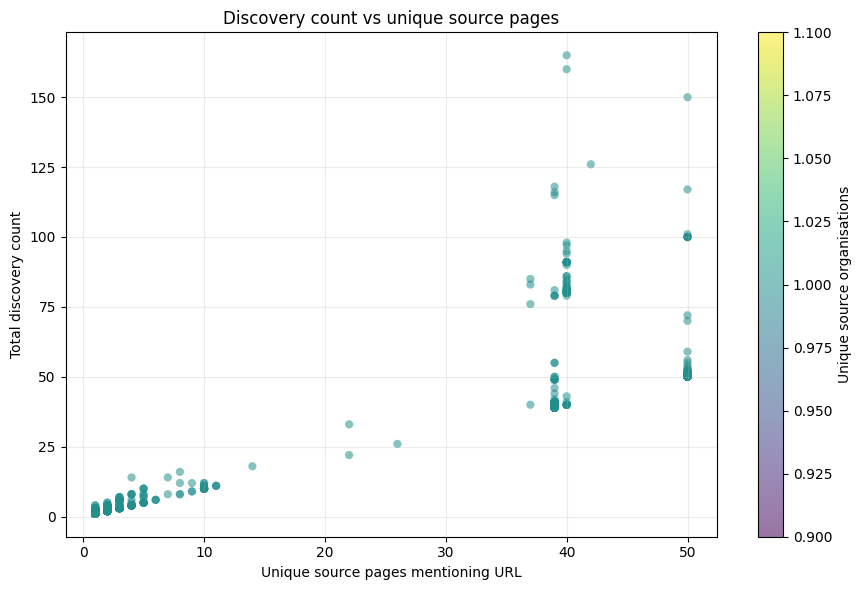

In [189]:
# visualise repeated discovery versus unique source pages
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    url_discovery_summary_df["unique_source_pages"],
    url_discovery_summary_df["discovery_count"],
    s=(url_discovery_summary_df["unique_source_organisations"] * 35),
    c=url_discovery_summary_df["unique_source_organisations"],
    alpha=0.55,
    edgecolors="none",
)

plt.title("Discovery count vs unique source pages")
plt.xlabel("Unique source pages mentioning URL")
plt.ylabel("Total discovery count")
plt.grid(True, alpha=0.25)

colorbar = plt.colorbar(scatter)
colorbar.set_label("Unique source organisations")

plt.tight_layout()
plt.show()

**Observation:** The scatter plot helps separate URLs that are repeatedly discovered from many pages from URLs that are repeated only a few times.


URLs in the upper-right are repeatedly discovered from many crawl pages, which often indicates navigation hubs or pages that are prominent across the website.

URLs near the top of this table are repeatedly found across the crawl. These may be important hub pages, high-priority review candidates, or pages duplicated by navigation menus.

### 8. Common URL sections

In [190]:
# summarise common URL sections by source
url_section_summary_df = (
    eda_df
    .groupby(["source_organisation", "url_section"], dropna=False)
    .agg(
        rows=("full_url", "size"),
        unique_urls=("full_url", "nunique"),
    )
    .reset_index()
    .sort_values("rows", ascending=False)
    .reset_index(drop=True)
)

url_section_summary_df.head(25)

,source_organisation,url_section,rows,unique_urls
0,kanker.nl,kankersoorten,1830,717
1,iknl.nl,kankersoorten,1383,231
2,nfk.nl,themas,1141,44
3,nfk.nl,organisatie,915,57
4,iknl.nl,nkr,818,46
5,thuisarts.nl,overzicht,810,315
6,iknl.nl,over-iknl,577,22
7,iknl.nl,kankeratlas,509,13
8,kanker.nl,soorten-behandelingen,484,126
9,iknl.nl,kanker-en-leven,430,12


**Observation:** The most common URL sections relate strongly to cancer types, themes, care and service pages, which supports the focus on patient-navigation topics.


### 9. Quick visual checks

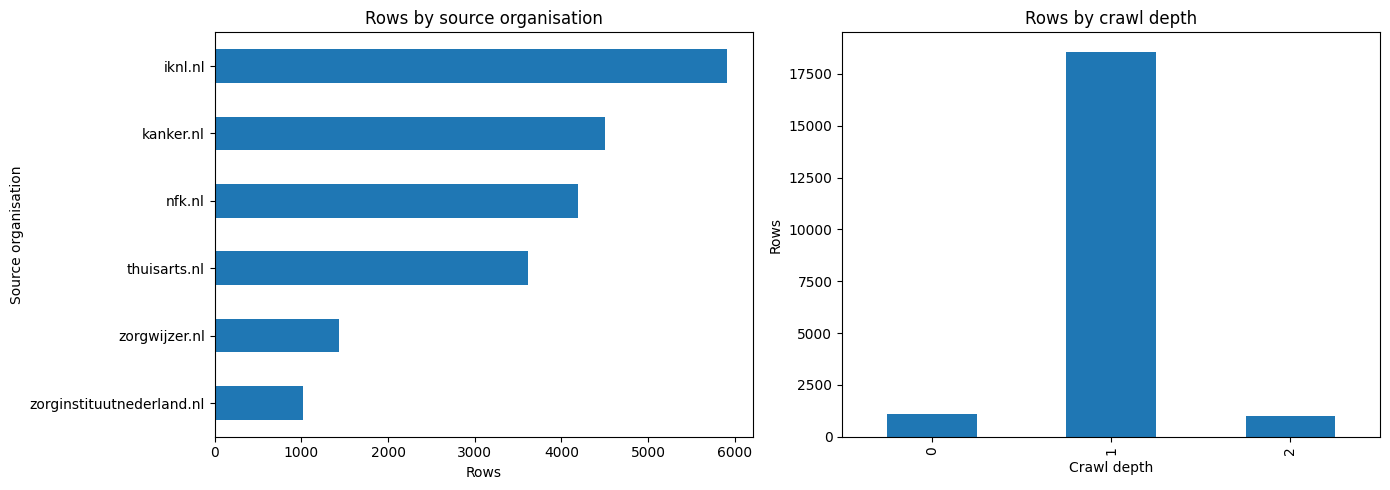

In [191]:
# compare source coverage and crawl depth visually
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

source_summary_df.sort_values("rows").plot.barh(
    x="source_organisation",
    y="rows",
    ax=axes[0],
    legend=False,
    title="Rows by source organisation",
)
axes[0].set_xlabel("Rows")
axes[0].set_ylabel("Source organisation")

depth_summary_df.plot.bar(
    x="depth",
    y="rows",
    ax=axes[1],
    legend=False,
    title="Rows by crawl depth",
)
axes[1].set_xlabel("Crawl depth")
axes[1].set_ylabel("Rows")

plt.tight_layout()
plt.show()

The EDA shows how broad the crawl is, where duplicates are concentrated, and which columns are ready for manual review or later shortlist filtering.

## Keyword Development Support

Before defining the keyword lists, the translated discovered-link metadata is explored to identify frequent English words and phrases. This uses one row per unique URL so repeated navigation links do not dominate the keyword evidence.

### 1. Build text corpus for keyword exploration

In [192]:
# build an English text corpus from translated metadata
keyword_text_columns = [
    column for column in [
        "link_text_en",
        "url_section_en",
    ]
    if column in links_df.columns
]

# Use one row per URL so repeated menu/navigation links do not dominate keyword discovery.
# Only translated English fields are used here to support the English keyword list.
keyword_base_df = links_df.drop_duplicates(subset=["full_url"]).copy()
keyword_text_df = keyword_base_df[keyword_text_columns].fillna("").astype(str).copy()

keyword_text_df["keyword_source_text"] = (
    keyword_text_df
    .agg(" | ".join, axis=1)
    .str.lower()
    .str.replace(r"[^a-zA-Z0-9\s-]", " ", regex=True)
    .str.replace(r"[-_/]+", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

translated_keyword_corpus_summary_df = pd.DataFrame([
    {
        "metric": "Unique URLs used",
        "value": len(keyword_base_df),
    },
    {
        "metric": "Rows with translated keyword text",
        "value": (keyword_text_df["keyword_source_text"].str.len() > 0).sum(),
    },
    {
        "metric": "Translated columns used",
        "value": "; ".join(keyword_text_columns),
    },
])

translated_keyword_corpus_summary_df

,metric,value
0,Unique URLs used,3819
1,Rows with translated keyword text,3819
2,Translated columns used,link_text_en; url_section_en


**Observation:** The translated keyword corpus uses **3,819 unique URLs**, with translated English text available for all **3,819 URLs**. This gives complete English metadata coverage for keyword development.


### 2. Frequent single words

In [193]:
# remove common words before frequency analysis
keyword_stopwords = {
    "a", "an", "and", "are", "as", "at", "be", "by", "for", "from",
    "has", "have", "how", "in", "into", "is", "it", "its", "of",
    "on", "or", "that", "the", "their", "this", "to", "with", "you",
    "your", "we", "our", "they", "them", "more", "read", "page",
    "pages", "home", "homepage", "overview", "about", "all",
    "information", "info", "website", "websites", "click", "view",
    "what", "where", "when", "which", "who", "why", "pdf", "file",
    "see", "go", "back", "next", "previous", "menu", "search",
    "contact", "cookie", "cookies", "privacy", "login", "account",
    "news", "newsletter", "subscribe", "organization", "organisation",
    "topic", "topics", "theme", "themes", "image", "title", "minutes",
    "video", "videos",
}

all_tokens = []
for text in keyword_text_df["keyword_source_text"]:
    all_tokens.extend(
        token for token in text.split()
        if len(token) > 2 and token not in keyword_stopwords and not token.isdigit()
    )

word_frequency_df = (
    pd.DataFrame(Counter(all_tokens).most_common(40), columns=["word", "count"])
)

word_frequency_df

,word,count
0,cancer,1188
1,cancers,960
2,care,327
3,consequences,190
4,treatments,175
5,help,132
6,species,126
7,health,126
8,insured,122
9,treatment,119


**Observation:** Frequent translated words such as `cancer`, `care`, `consequences`, `treatments`, `treatment`, `help` and `health` confirm that the discovered metadata is aligned with the project domain.


### 3. Frequent two- and three-word phrases

In [194]:
# create phrase counts from cleaned tokens
def make_ngrams(tokens, n):
    return [" ".join(tokens[index:index + n]) for index in range(len(tokens) - n + 1)]

bigram_counter = Counter()
trigram_counter = Counter()

for text in keyword_text_df["keyword_source_text"]:
    tokens = [
        token for token in text.split()
        if len(token) > 2 and token not in keyword_stopwords and not token.isdigit()
    ]
    bigram_counter.update(make_ngrams(tokens, 2))
    trigram_counter.update(make_ngrams(tokens, 3))

phrase_frequency_df = pd.concat(
    [
        pd.DataFrame(bigram_counter.most_common(25), columns=["phrase", "count"]).assign(phrase_length=2),
        pd.DataFrame(trigram_counter.most_common(25), columns=["phrase", "count"]).assign(phrase_length=3),
    ],
    ignore_index=True,
)

phrase_frequency_df.sort_values(["count", "phrase_length"], ascending=[False, True]).head(30)

,phrase,count,phrase_length
0,cancer cancers,429,2
1,consequences cancer,174,2
2,species treatments,126,2
3,insured care,120,2
4,experiences others,95,2
5,breast cancer,94,2
6,help support,87,2
7,cancer consequences,72,2
25,cancer consequences cancer,72,3
8,cervical cancer,70,2


**Observation:** Frequent phrases such as `breast cancer`, `cervical cancer`, `prostate cancer`, `insured care`, `health insurance`, `help support` and `consequences cancer` helped sense-check the topic and support keyword lists.


### 4. Keyword Word Clouds

Word clouds provide a quick visual sense-check of the translated terms and phrases that appear most often in the discovered link metadata.

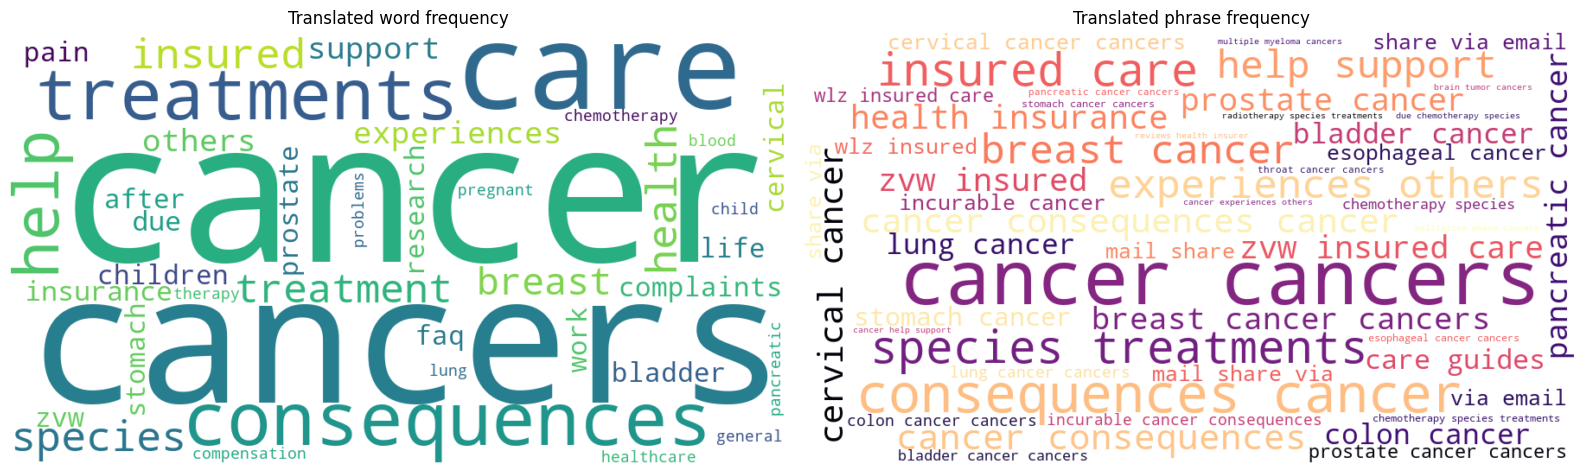

In [195]:
# show word clouds when the optional package is available
if WordCloud is None:
    print("Install wordcloud to display word-cloud visuals: pip install wordcloud")
else:
    wordcloud_fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    word_cloud = WordCloud(
        width=900,
        height=500,
        background_color="white",
        colormap="viridis",
        max_words=80,
    ).generate_from_frequencies(dict(zip(word_frequency_df["word"], word_frequency_df["count"])))

    phrase_cloud_data = phrase_frequency_df.sort_values(
        ["count", "phrase_length"],
        ascending=[False, True]
    ).head(60)
    phrase_cloud = WordCloud(
        width=900,
        height=500,
        background_color="white",
        colormap="magma",
        max_words=60,
    ).generate_from_frequencies(dict(zip(phrase_cloud_data["phrase"], phrase_cloud_data["count"])))

    axes[0].imshow(word_cloud, interpolation="bilinear")
    axes[0].set_title("Translated word frequency")
    axes[0].axis("off")

    axes[1].imshow(phrase_cloud, interpolation="bilinear")
    axes[1].set_title("Translated phrase frequency")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

**Observation:** The word clouds provide a quick visual check of the dominant English terms and phrases before applying the formal keyword filters.


### 5. Keyword development notes

The translated word-frequency and phrase-frequency outputs were used as a sense-check for the manual keyword list. High-frequency healthcare terms helped confirm expected topic language, while frequent navigation terms informed the noise keyword list.

### 6. Define keyword list

In [196]:
noise_keywords = [
    # English
    "login", "log in", "signin", "sign in", "sign-in", "register",
    "registration", "account", "profile", "my account", "password", "cookie",
    "cookies", "privacy", "privacy policy", "terms", "conditions", "contact",
    "contact us", "jobs", "vacancies", "careers", "work with us", "donate",
    "donation", "fundraising", "news", "press", "media", "events", "calendar",
    "rss", "feed", "search", "sitemap", "newsletter", "subscribe",
    "unsubscribe",
    # Dutch
    "inloggen", "login", "aanmelden", "registreren", "account", "profiel",
    "wachtwoord", "cookie", "cookies", "privacy", "privacyverklaring",
    "voorwaarden", "contact", "neem contact", "vacatures", "werken bij",
    "baan", "banen", "doneren", "donatie", "gift", "nieuws", "pers",
    "evenement", "evenementen", "agenda", "rss", "zoeken", "zoek", "sitemap",
    "nieuwsbrief", "abonneren",
]

noise_path_patterns = [
    (
        r"/(login|inloggen|signin|sign-in|account|mijn|profiel|register|"
        r"registreren)(/|$)"
    ),
    (
        r"/(cookie|cookies|privacy|contact|vacature|vacatures|werken-bij|"
        r"jobs|careers)(/|$)"
    ),
    (
        r"/(doneren|donatie|donate|donation|nieuws|news|evenementen|"
        r"events|agenda|rss)(/|$)"
    ),
    r"/(zoeken|search)(/|$|\?)",
    r"[?&](q|query|search|s)=",
]

csn_keyword_map = {
    "referrals_process": [
        "referral", "referrals", "refer", "referred", "referring",
        "referral process", "pathway", "care pathway", "patient pathway",
        "care route", "navigation", "general practitioner", "gp",
        "specialist referral", "hospital referral", "verwijzing",
        "verwijzingen", "verwijzen", "doorverwijzing", "doorverwijzen",
        "verwijsbrief", "verwijstraject", "zorgpad", "patientenpad",
        "patientroute", "huisarts", "specialist", "naar het ziekenhuis",
        "zorgtraject",
    ],
    "waiting_times": [
        "waiting time", "waiting times", "wait time", "wait times",
        "waiting list", "waiting period", "access time", "lead time", "delay",
        "delays", "appointment delay", "wachtlijst", "wachtlijsten",
        "wachttijd", "wachttijden", "wachten", "toegangstijd", "doorlooptijd",
        "vertraging", "uitstel", "afspraak maken",
    ],
    "treatment_decisions": [
        "treatment decision", "treatment decisions", "treatment choice",
        "treatment choices", "shared decision", "shared decision making",
        "decision aid", "decision support", "choose treatment",
        "choosing treatment", "treatment options", "treatment plan",
        "benefits and risks", "side effects", "pros and cons",
        "preference-sensitive", "behandelkeuze", "behandelkeuzes",
        "behandelbeslissing", "behandelbeslissingen", "samen beslissen",
        "gedeelde besluitvorming", "keuzehulp", "beslissingshulp",
        "behandelopties", "behandelplan", "voor- en nadelen", "bijwerkingen",
    ],
    "second_opinions": [
        "second opinion", "second opinions", "another opinion",
        "independent opinion", "expert opinion", "specialist opinion",
        "ask another doctor", "second assessment", "tweede mening",
        "second opinion", "ander oordeel", "onafhankelijk oordeel",
        "deskundig oordeel", "expert opinion", "andere arts",
        "andere specialist",
    ],
    "additional_support": [
        "support", "additional support", "practical support",
        "psychological support", "emotional support", "social support",
        "peer support", "support group", "support groups", "aftercare",
        "survivorship", "rehabilitation", "financial support",
        "work and cancer", "family support", "carer", "caregiver",
        "palliative care", "home care", "ondersteuning", "extra ondersteuning",
        "praktische hulp", "psychologische hulp", "emotionele steun",
        "lotgenoten", "lotgenotengroep", "nazorg", "revalidatie",
        "financiele hulp", "werk en kanker", "mantelzorg", "naasten",
        "palliatieve zorg", "thuiszorg", "hulp bij kanker",
    ],
    "communication_understanding": [
        "communication", "communicate", "communicating", "understand",
        "understanding", "explanation", "explain", "plain language",
        "health literacy", "interpreter", "translation", "translator",
        "questions to ask", "ask questions", "consultation",
        "conversation with doctor", "medical terms", "information needs",
        "informed consent", "communicatie", "communiceren", "begrijpen",
        "uitleg", "toelichting", "duidelijke taal", "gezondheidsvaardigheden",
        "tolk", "vertaling", "vertaler", "vragen stellen", "vragen aan arts",
        "gesprek met arts", "consult", "spreekuur", "medische termen",
        "informatiebehoefte", "toestemming", "informed consent",
    ],
}

### 7. Keyword coverage check

In [197]:
# check how often topic keywords appear in the corpus
def count_keyword_hits(text_series, keywords):
    text_blob = " ".join(text_series.fillna("").astype(str).str.lower())

    hits = []
    for keyword in keywords:
        keyword_norm = str(keyword).lower()
        count = len(re.findall(rf"(?<![a-z0-9]){re.escape(keyword_norm)}(?![a-z0-9])", text_blob))
        if count > 0:
            hits.append({"keyword": keyword, "hit_count": count})

    return hits

keyword_topic_coverage_rows = []
text_for_keyword_coverage = keyword_text_df["keyword_source_text"]

for topic, keywords in csn_keyword_map.items():
    hits = count_keyword_hits(text_for_keyword_coverage, keywords)
    keyword_topic_coverage_rows.append({
        "topic": topic,
        "keywords_defined": len(keywords),
        "keywords_found_in_discovered_links": len(hits),
        "total_keyword_hits": sum(item["hit_count"] for item in hits),
        "top_matching_keywords": "; ".join(
            item["keyword"] for item in sorted(hits, key=lambda item: item["hit_count"], reverse=True)[:8]
        ),
    })

keyword_topic_coverage_df = pd.DataFrame(keyword_topic_coverage_rows)
keyword_topic_coverage_df

,topic,keywords_defined,keywords_found_in_discovered_links,total_keyword_hits,top_matching_keywords
0,referrals_process,29,4,11,gp; specialist; referral; general practitioner
1,waiting_times,21,2,3,delay; waiting period
2,treatment_decisions,28,7,29,side effects; treatment plan; shared decision;...
3,second_opinions,16,0,0,
4,additional_support,35,6,135,support; palliative care; aftercare; rehabilit...
5,communication_understanding,38,7,16,explanation; communication; understand; commun...


This check does not replace manual judgement, but it shows whether the proposed topic keywords appear in the discovered link metadata and helps identify topics that may need extra Dutch or English synonyms.

Keyword lists were created that flag content that is unlikely to help answer patient navigation questions and maps Dutch and English terms to the six CSN topic areas.

These terms are used to identify potentially relevant pages to be manually reviewed.

### 4. Prepare matching functions

In [198]:
# choose available columns for keyword matching
preferred_text_columns = [
    "link_text",
    "link_text_en",
    "href",
    "full_url",
    "url_section",
    "url_section_en",
    "page_title",
    "page_title_en",
]

text_columns = [
    column for column in preferred_text_columns
    if column in links_df.columns
]


def normalize_text(value):
    """Return lower-case text with accents and repeated spaces removed."""
    if pd.isna(value):
        return ""

    text = unicodedata.normalize("NFKD", str(value))
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = text.lower()

    return re.sub(r"\s+", " ", text).strip()


def keyword_pattern(keyword):
    """Create a regex pattern for matching a keyword or phrase."""
    escaped = re.escape(normalize_text(keyword))

    # Match phrases across spaces, hyphens, slashes and underscores.
    escaped = escaped.replace(r"\ ", r"[\s_\-/]+")

    return re.compile(rf"(?<![a-z0-9]){escaped}(?![a-z0-9])")

The available link metadata fields have been combined into one text field with the text has been normalised, making it easier to search.

### 5. Compile patterns and create search text

In [199]:
# compile keyword patterns and build searchable text
noise_patterns = [keyword_pattern(keyword) for keyword in noise_keywords]
noise_path_regexes = [re.compile(pattern) for pattern in noise_path_patterns]

topic_patterns = {
    topic: [(keyword, keyword_pattern(keyword)) for keyword in keywords]
    for topic, keywords in csn_keyword_map.items()
}

links_for_review_df = links_df.copy()

# Combine available link metadata into one field for keyword matching.
links_for_review_df["_search_text"] = (
    links_for_review_df[text_columns]
    .fillna("")
    .astype(str)
    .agg(" | ".join, axis=1)
)

links_for_review_df["_search_text_norm"] = (
    links_for_review_df["_search_text"]
    .map(normalize_text)
)

### 6. Flag obvious noise

In [200]:
# flag links that look like navigation or admin noise
if "full_url" in links_for_review_df.columns:
    url_text = links_for_review_df["full_url"].fillna("").map(normalize_text)
elif "href" in links_for_review_df.columns:
    url_text = links_for_review_df["href"].fillna("").map(normalize_text)
else:
    url_text = pd.Series([""] * len(links_for_review_df), index=links_for_review_df.index)

links_for_review_df["is_obvious_noise"] = (
    links_for_review_df["_search_text_norm"].map(
        lambda text: any(pattern.search(text) for pattern in noise_patterns)
    )
    | url_text.map(
        lambda text: any(pattern.search(text) for pattern in noise_path_regexes)
    )
)

print(f"Flagged {links_for_review_df['is_obvious_noise'].sum():,} noise links")

Flagged 2,463 noise links


**Observation:** The noise rules flagged **2,463 links** as likely non-content or navigation/admin pages, reducing the amount of irrelevant material before topic matching.


Links are flagged as noise if their metadata or URL path suggests they are not relevant.

### 7. Identify topic matches

In [201]:
# return matched topics and keywords for each row
def find_topic_matches(row):
    """Return matched CSN topics and keywords for a single link."""
    combined_text = row["_search_text_norm"]
    matched_topics = []
    matched_keywords = []

    for topic, patterns in topic_patterns.items():
        topic_keywords = [
            keyword for keyword, pattern in patterns
            if pattern.search(combined_text)
        ]

        if topic_keywords:
            matched_topics.append(topic)
            matched_keywords.extend(
                f"{topic}:{keyword}" for keyword in topic_keywords
            )

    return pd.Series({
        "matched_topics": "; ".join(matched_topics),
        "matched_keywords": "; ".join(matched_keywords),
        "_topic_count": len(matched_topics),
        "_keyword_count": len(matched_keywords),
    })


match_columns = links_for_review_df.apply(find_topic_matches, axis=1)
links_for_review_df = pd.concat([links_for_review_df, match_columns], axis=1)

Each link is checked against the six CSN topic keyword lists, with links able to match more than one topic area.

### 8. Create shortlist DataFrame

In [202]:
# keep non-noise links with at least one topic match
shortlisted_links_review_df = (
    links_for_review_df
    .loc[
        lambda df: (
            ~df["is_obvious_noise"]
            & (df["_topic_count"] > 0)
        )
    ]
    .copy()
)

shortlisted_links_review_df["review_decision"] = ""
shortlisted_links_review_df["reviewer"] = ""
shortlisted_links_review_df["review_notes"] = ""

helper_columns = [
    "_search_text",
    "_search_text_norm",
    "_topic_count",
    "_keyword_count",
    "is_obvious_noise",
]

review_columns = [
    "matched_topics",
    "matched_keywords",
    "review_decision",
    "reviewer",
    "review_notes",
]

base_columns = [
    column for column in shortlisted_links_review_df.columns
    if column not in helper_columns + review_columns
]

shortlisted_links_review_df = (
    shortlisted_links_review_df
    .drop(
        columns=[
            column for column in helper_columns
            if column in shortlisted_links_review_df.columns
        ]
    )
    .sort_values(["matched_topics", "full_url"], ascending=[True, True])
    .reset_index(drop=True)
    [base_columns + review_columns]
)

print(f"Created {len(shortlisted_links_review_df):,} links for manual review")

shortlisted_links_review_df.head(20)

Created 1,239 links for manual review


,source_organisation,source_page,depth,link_text,link_text_en,href,full_url,url_section,url_section_en,is_selected,is_noise,matched_topics,matched_keywords,review_decision,reviewer,review_notes
0,iknl.nl,https://iknl.nl/kankersoorten/baarmoederkanker,1,informatie over palliatieve zorg,information about palliative care,https://iknl.nl/kankersoorten/baarmoederkanker...,https://iknl.nl/kankersoorten/baarmoederkanker...,kankersoorten,cancers,NaN,NaN,additional_support,additional_support:palliative care; additional...,,,
1,iknl.nl,https://iknl.nl/,0,Palliatieve zorg ->,Palliative care ->,/palliatieve-zorg,https://iknl.nl/palliatieve-zorg,palliatieve-zorg,palliative care,NaN,NaN,additional_support,additional_support:palliative care; additional...,,,
2,iknl.nl,https://iknl.nl/nieuws,1,Palliatieve zorg ->,Palliative care ->,/palliatieve-zorg,https://iknl.nl/palliatieve-zorg,palliatieve-zorg,palliative care,NaN,NaN,additional_support,additional_support:palliative care; additional...,,,
3,iknl.nl,https://iknl.nl/projecten,1,Palliatieve zorg ->,Palliative care ->,/palliatieve-zorg,https://iknl.nl/palliatieve-zorg,palliatieve-zorg,palliative care,NaN,NaN,additional_support,additional_support:palliative care; additional...,,,
4,iknl.nl,https://iknl.nl/trials,1,Palliatieve zorg ->,Palliative care ->,/palliatieve-zorg,https://iknl.nl/palliatieve-zorg,palliatieve-zorg,palliative care,NaN,NaN,additional_support,additional_support:palliative care; additional...,,,
5,iknl.nl,https://iknl.nl/webshop,1,Palliatieve zorg ->,Palliative care ->,/palliatieve-zorg,https://iknl.nl/palliatieve-zorg,palliatieve-zorg,palliative care,NaN,NaN,additional_support,additional_support:palliative care; additional...,,,
6,iknl.nl,https://iknl.nl/nkr,1,Palliatieve zorg ->,Palliative care ->,/palliatieve-zorg,https://iknl.nl/palliatieve-zorg,palliatieve-zorg,palliative care,NaN,NaN,additional_support,additional_support:palliative care; additional...,,,
7,iknl.nl,https://iknl.nl/nkr/over-nkr,1,Palliatieve zorg ->,Palliative care ->,/palliatieve-zorg,https://iknl.nl/palliatieve-zorg,palliatieve-zorg,palliative care,NaN,NaN,additional_support,additional_support:palliative care; additional...,,,
8,iknl.nl,https://iknl.nl/nkr/registratie,1,Palliatieve zorg ->,Palliative care ->,/palliatieve-zorg,https://iknl.nl/palliatieve-zorg,palliatieve-zorg,palliative care,NaN,NaN,additional_support,additional_support:palliative care; additional...,,,
9,iknl.nl,https://iknl.nl/nkr/cijfers-op-maat,1,Palliatieve zorg ->,Palliative care ->,/palliatieve-zorg,https://iknl.nl/palliatieve-zorg,palliatieve-zorg,palliative care,NaN,NaN,additional_support,additional_support:palliative care; additional...,,,


**Observation:** After removing obvious noise and applying topic keywords, **1,239 links** remain for manual review.


The final shortlist keeps the links that are not obvious noise and match at least one CSN topic area. Review columns are then added for manual review.

#

# Deduplicate and prepare manual review shortlist

Previously, a shortlist based on keyword matching and basic noise removal was created.

This section deduplicates that shortlist so only each unique page appears once in the dataset, creating a list that can be manually reviewed.


### 1. Copy shortlist and check required columns

In [203]:
# prepare shortlisted rows for deduplication
manual_source_df = shortlisted_links_review_df.copy()

required_columns = [
    "full_url",
    "source_organisation",
    "matched_topics",
    "matched_keywords",
]

for column in required_columns:
    if column not in manual_source_df.columns:
        manual_source_df[column] = ""

review_columns = [
    "review_decision",
    "reviewer",
    "review_notes",
]

for column in review_columns:
    if column not in manual_source_df.columns:
        manual_source_df[column] = ""

print(f"Loaded {len(manual_source_df):,} shortlisted rows")

Loaded 1,239 shortlisted rows


**Observation:** The shortlist is copied before deduplication so the original matched rows remain available if detailed checking is needed.


### 2. Helper functions

In [204]:
# helper functions combine repeated duplicate values
def split_values(value):
    """Split semi-colon or pipe-separated values into clean parts."""
    if pd.isna(value):
        return []

    parts = []

    for chunk in str(value).replace("|", ";").split(";"):
        cleaned = chunk.strip()

        if cleaned and cleaned.lower() not in {"nan", "none"}:
            parts.append(cleaned)

    return parts


def combine_unique(values):
    """Combine repeated topic or keyword values in first-seen order."""
    seen = []

    for value in values:
        for part in split_values(value):
            if part not in seen:
                seen.append(part)

    return "; ".join(seen)


def combine_unique_text(values):
    """Combine repeated text values in first-seen order."""
    seen = []

    for value in values:
        if pd.isna(value):
            continue

        cleaned = str(value).strip()

        if cleaned and cleaned.lower() not in {"nan", "none"} and cleaned not in seen:
            seen.append(cleaned)

    return "; ".join(seen)

Some URLS appear more than once because the same page may have been discovered through different link text, topic matches or source paths.

This helper function combines repeated values while maintaining unique information.

### 3. Deduplicate rows by URL

In [205]:
# aggregate duplicate URLs into one review row
representative_rows = (
    manual_source_df
    .drop_duplicates(subset=["full_url"], keep="first")
    .set_index("full_url")
)

duplicate_summary = (
    manual_source_df
    .groupby("full_url", dropna=False)
    .agg(
        source_organisation=("source_organisation", combine_unique_text),
        matched_topics=("matched_topics", combine_unique),
        matched_keywords=("matched_keywords", combine_unique),
        review_decision=("review_decision", combine_unique_text),
        reviewer=("reviewer", combine_unique_text),
        review_notes=("review_notes", combine_unique_text),
    )
)

deduplicated_df = representative_rows.copy()

for column in duplicate_summary.columns:
    deduplicated_df[column] = duplicate_summary[column]

deduplicated_df = deduplicated_df.reset_index()

print(f"Deduplicated to {len(deduplicated_df):,} unique URLs")
print(f"Removed {len(manual_source_df) - len(deduplicated_df):,} duplicate rows")

Deduplicated to 250 unique URLs
Removed 989 duplicate rows


**Observation:** Deduplication reduces the shortlist from **1,239 rows** to **250 unique URLs**, removing **989 duplicate rows** before manual review.


### 4. Create final manual review DataFrame

In [206]:
# select final columns for manual review export
output_columns = ["source_organisation"]

if "page_title" in deduplicated_df.columns:
    output_columns.append("page_title")
elif "page_title_en" in deduplicated_df.columns:
    output_columns.append("page_title_en")

output_columns += [
    "link_text",
    "link_text_en",
    "full_url",
    "matched_topics",
    "matched_keywords",
    "review_decision",
    "reviewer",
    "review_notes",
]

for column in output_columns:
    if column not in deduplicated_df.columns:
        deduplicated_df[column] = ""

manual_review_df = (
    deduplicated_df[output_columns]
    .sort_values(["matched_topics", "full_url"], ascending=[True, True])
    .reset_index(drop=True)
)

print(f"Manual review dataframe contains {len(manual_review_df):,} unique URLs")

manual_review_df.to_csv(
    MANUAL_REVIEW_PATH,
    index=False
)
print(f"Manual review dataset saved: {MANUAL_REVIEW_PATH}")

manual_review_df.head(20)

Manual review dataframe contains 250 unique URLs
Manual review dataset saved: data/manual_review_links_df.csv


,source_organisation,link_text,link_text_en,full_url,matched_topics,matched_keywords,review_decision,reviewer,review_notes
0,iknl.nl,informatie over palliatieve zorg,information about palliative care,https://iknl.nl/kankersoorten/baarmoederkanker...,additional_support,additional_support:palliative care; additional...,,,
1,iknl.nl,Palliatieve zorg ->,Palliative care ->,https://iknl.nl/palliatieve-zorg,additional_support,additional_support:palliative care; additional...,,,
2,iknl.nl,Kerncijfers palliatieve zorg,Key figures for palliative care,https://iknl.nl/palliatieve-zorg/kerncijfers-p...,additional_support,additional_support:palliative care; additional...,,,
3,iknl.nl,Kwaliteit van Leven,Quality of Life,https://iknl.nl/palliatieve-zorg/kwaliteit-van...,additional_support,additional_support:palliative care; additional...,,,
4,iknl.nl,Proactief gegevens delen,Proactively share data,https://iknl.nl/palliatieve-zorg/proactief-geg...,additional_support,additional_support:palliative care; additional...,,,
5,iknl.nl,Symptoommanagement in de palliatieve fase,Symptom management in the palliative phase,https://iknl.nl/palliatieve-zorg/symptoommonit...,additional_support,additional_support:palliative care; additional...,,,
6,iknl.nl,Uitgezaaide kanker,Metastatic cancer,https://iknl.nl/palliatieve-zorg/uitgezaaide-k...,additional_support,additional_support:palliative care; additional...,,,
7,iknl.nl,Palliatieve zorg,Palliative care,https://iknl.nl/themas/palliatieve-zorg,additional_support,additional_support:palliative care; additional...,,,
8,nfk.nl,Verhoogd risico op kanker: wat vind jij van de...,Increased risk of cancer: what do you think of...,https://nfk.nl/inzichten/doneer-je-ervaring-pe...,additional_support,additional_support:support; additional_support...,,,
9,nfk.nl,Gesprekshulp 'Werk en kanker',Discussion aid 'Work and cancer',https://nfk.nl/middelen/producten/gesprekshulp,additional_support,additional_support:work and cancer; additional...,,,


**Observation:** The final manual review dataset contains **250 unique URLs** and is exported for the next review stage.


This creates the final deduplicated manual review dataframe.

## Summary

This notebook created the first-stage link discovery and manual review dataset for the CSN cancer navigation knowledge base.

Key results:

- **20,659 links** were discovered across **6 approved source organisations**.
- These links represent **3,819 unique URLs**, showing that many pages were discovered repeatedly across website navigation.
- **1,868 URLs** appeared more than once, so duplicate analysis and deduplication were important parts of the workflow.
- The translated metadata fields `link_text_en` and `url_section_en` are complete, with **0 missing values** after preserving the IKNL translations.
- English word-frequency, phrase-frequency and word-cloud analysis supported the keyword development process.
- The noise rules flagged **2,463 links** as likely navigation, admin or non-content pages.
- Topic keyword matching created a shortlist of **1,239 links** for review.
- Deduplication reduced this shortlist to **250 unique URLs** for manual review.

Final exported files:

- `data/discovered_links_df.csv`: full discovered links dataset.
- `data/url_discovery_summary_df.csv`: one row per URL with discovery frequency and source-page coverage.
- `data/manual_review_links_df.csv`: final deduplicated manual review dataset.

Overall, the notebook moves from broad website discovery to a focused, deduplicated review set that can be used to select reliable pages for the next stage of the CSN knowledge base.
